# Clase 7 — Explorar: de los bandits a la cueva

**RL a ciegas** · curso de aprendizaje por refuerzo (*reinforcement learning*, RL) · vía profunda

Basado en Sutton & Barto, cap. 2 (2.1–2.7: bandits, $\varepsilon$-greedy, valores iniciales optimistas y UCB), en Stanford CS234 (Brunskill), clases 9 a 12, en Bellemare et al. (2016) para la bonificación por conteo, en Ecoffet et al. (2021) para Go-Explore y en Machado et al. (2018) para las acciones pegajosas.

**La pregunta de hoy:** ¿cuánto vale probar algo que todavía no conocés, si probar cuesta y la recompensa puede no llegar nunca?

En la clase 6 el agente probaba tirando una moneda ($\varepsilon$-greedy) y vimos que solo aprende de donde pasa. Hoy buscamos maneras de probar que apunten adonde todavía no se sabe. Primero en el problema más chico posible, un solo estado, y después en la cueva:

1. **El bandit de cuatro anuncios**: un estado, cuatro acciones, una recompensa por vez.
2. **Cuánto se pierde por probar**: el arrepentimiento (*regret*) de una prueba A/B fija, de $\varepsilon$-greedy y de UCB.
3. **UCB y la bonificación**: una cuenta a mano de qué anuncio elige.
4. **$\varepsilon$-greedy en la cueva grande**, con la recompensa solo en la salida.
5. **Optimismo y conteos** en la cueva: el mapa de visitas.
6. **Go-Explore**: primero volver, después explorar.
7. **Cuando volver no es exacto**: acciones pegajosas y piso resbaloso.

Y un ejercicio: cambiar $\varepsilon$ y la bonificación.

> Cómo usar este notebook: ejecutar las celdas en orden (Colab: *Entorno de ejecución → Ejecutar todas*). Tarda alrededor de un minuto.

## Preparación

La primera celda escribe el archivo `cave_env.py` con **la cueva** de todo el curso. Así el notebook funciona solo, también en Colab. No hace falta leerla.

In [1]:
%%writefile cave_env.py
"""
cave_env.py — La cueva a ciegas (entorno del mini curso de RL).

Una grilla discreta. El agente no ve el mapa: solo se entera de que hay una
pared cuando choca contra ella (en el juego, la pared se pinta de gris claro).
La salida es el cuadrado verde 'G'.

API mínima (estilo Gymnasium, sin dependencias):
    env = CaveEnv()
    s = env.reset()                 # estado = índice entero de la casilla
    s, r, done, info = env.step(a)  # a en {0:arriba, 1:derecha, 2:abajo, 3:izquierda}
    info["bump"]                    # True si chocó con una pared

Para la clase 4 (planificar con mapa): env.P[s, a, s'] y env.R[s, a].
"""
import numpy as np

CAVE_MAP = [
    "##############",
    "#S...#.......#",
    "#.##.#.####..#",
    "#.#..#....#..#",
    "#.#.####..#.##",
    "#.#......##..#",
    "#.####.#..#..#",
    "#......#.##..#",
    "###.####....G#",
    "##############",
]

ACTIONS = {0: (-1, 0), 1: (0, 1), 2: (1, 0), 3: (0, -1)}
ACTION_NAMES = ["↑", "→", "↓", "←"]


class CaveEnv:
    def __init__(self, cave_map=CAVE_MAP, goal_reward=1.0, step_reward=0.0,
                 bump_reward=0.0, slip=0.0, max_steps=200, seed=None):
        self.grid = np.array([list(row) for row in cave_map])
        self.H, self.W = self.grid.shape
        self.goal_reward, self.step_reward, self.bump_reward = goal_reward, step_reward, bump_reward
        self.slip, self.max_steps = slip, max_steps
        self.rng = np.random.default_rng(seed)
        self.free = [(r, c) for r in range(self.H) for c in range(self.W) if self.grid[r, c] != "#"]
        self.pos2s = {p: i for i, p in enumerate(self.free)}
        self.nS, self.nA = len(self.free), 4
        self.start = self.pos2s[tuple(np.argwhere(self.grid == "S")[0])]
        self.goal = self.pos2s[tuple(np.argwhere(self.grid == "G")[0])]
        self._build_model()
        self.reset()

    # ---------- dinámica ----------
    def _move(self, s, a):
        r, c = self.free[s]
        dr, dc = ACTIONS[a]
        nr, nc = r + dr, c + dc
        if self.grid[nr, nc] == "#":
            return s, True
        return self.pos2s[(nr, nc)], False

    def _reward(self, s_next, bump):
        if s_next == self.goal:
            return self.goal_reward
        return self.step_reward + (self.bump_reward if bump else 0.0)

    def _build_model(self):
        """Modelo del mundo: P[s,a,s'] y R[s,a] (recompensa esperada). La meta es absorbente."""
        nS, nA = self.nS, self.nA
        self.P = np.zeros((nS, nA, nS))
        self.R = np.zeros((nS, nA))
        for s in range(nS):
            for a in range(nA):
                if s == self.goal:
                    self.P[s, a, s] = 1.0
                    continue
                # con prob 1-slip va adonde quiere; con slip, a una dirección perpendicular
                outcomes = [(a, 1 - self.slip)]
                if self.slip > 0:
                    outcomes += [((a + 1) % 4, self.slip / 2), ((a + 3) % 4, self.slip / 2)]
                for aa, p in outcomes:
                    s2, bump = self._move(s, aa)
                    self.P[s, a, s2] += p
                    self.R[s, a] += p * self._reward(s2, bump)

    def reset(self):
        self.s, self.t = self.start, 0
        self.touched = set()          # paredes descubiertas (para dibujar)
        return self.s

    def step(self, a):
        if self.slip > 0 and self.rng.random() < self.slip:
            a = (a + self.rng.choice([1, 3])) % 4
        s2, bump = self._move(self.s, a)
        if bump:
            r, c = self.free[self.s]
            dr, dc = ACTIONS[a]
            self.touched.add((r + dr, c + dc))
        rew = self._reward(s2, bump)
        self.s, self.t = s2, self.t + 1
        done = s2 == self.goal or self.t >= self.max_steps
        return s2, rew, done, {"bump": bump, "reached_goal": s2 == self.goal}

    # ---------- observaciones para Deep RL ----------
    def observe(self, s=None, kind="onehot"):
        s = self.s if s is None else s
        if kind == "onehot":
            x = np.zeros(self.nS, dtype=np.float32); x[s] = 1; return x
        r, c = self.free[s]
        if kind == "coords":
            return np.array([r / (self.H - 1), c / (self.W - 1)], dtype=np.float32)
        if kind == "coords+touch":   # posición + 4 "bigotes" que sienten paredes vecinas
            walls = [float(self.grid[r + dr, c + dc] == "#") for dr, dc in ACTIONS.values()]
            return np.array([r / (self.H - 1), c / (self.W - 1)] + walls, dtype=np.float32)
        raise ValueError(kind)

    # ---------- dibujo ----------
    def to_grid(self, values):
        g = np.full((self.H, self.W), np.nan)
        for s, (r, c) in enumerate(self.free):
            g[r, c] = values[s]
        return g

    def plot(self, values=None, policy=None, ax=None, title=None, cmap="magma",
             show_walls=True, path=None):
        import matplotlib.pyplot as plt
        if ax is None:
            _, ax = plt.subplots(figsize=(self.W * 0.5, self.H * 0.5))
        bg = np.zeros((self.H, self.W, 3))
        if show_walls:
            bg[self.grid == "#"] = 0.8      # gris claro: la pared "tocada"
        ax.imshow(bg)
        if values is not None:
            im = ax.imshow(self.to_grid(values), cmap=cmap, alpha=0.9)
            plt.colorbar(im, ax=ax, fraction=0.03)
        gr, gc = self.free[self.goal]
        ax.add_patch(plt.Rectangle((gc - .5, gr - .5), 1, 1, color="#2ecc71"))
        sr, sc = self.free[self.start]
        ax.text(sc, sr, "S", ha="center", va="center", color="w", fontsize=11, weight="bold")
        if policy is not None:
            for s, (r, c) in enumerate(self.free):
                if s != self.goal:
                    ax.text(c, r, ACTION_NAMES[int(policy[s])], ha="center", va="center",
                            color="cyan", fontsize=11)
        if path is not None:
            rc = np.array([self.free[s] for s in path])
            ax.plot(rc[:, 1], rc[:, 0], "-", color="#3498db", lw=2, alpha=.8)
        ax.set_xticks([]); ax.set_yticks([])
        if title: ax.set_title(title)
        return ax

Overwriting cave_env.py


Importamos la cueva y las bibliotecas de siempre. En la cueva, las convenciones son las de las clases 3 a 6: **+1 al entrar a la salida**, la salida es absorbente, el primer paso no se descuenta y $\gamma = 0{,}99$.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from cave_env import CaveEnv, ACTION_NAMES

SEMILLA = 0
np.random.seed(SEMILLA)
GAMMA = 0.99

La celda siguiente define las **herramientas** (los bandits, el agente que aprende en la cueva, Go-Explore y los dibujos). Está plegada: no hace falta leerla, solo ejecutarla.

Como en la clase 6, todo lo que aprende en la cueva usa solo `env.reset` y `env.step`: nadie mira el mapa. La única excepción es Go-Explore cuando **restaura** el estado (sección 6), y eso es justamente lo que vamos a discutir.

In [3]:
# @title Herramientas (no hace falta leer esto)
# Herramientas: no hace falta leer esto
from collections import deque

COLORES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
plt.rcParams.update({
    "figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e6e6", "grid.linewidth": 0.8,
    "axes.edgecolor": "#888888", "axes.titlesize": 12, "font.size": 10.5,
    "lines.linewidth": 2, "axes.axisbelow": True,
})
COLOR_MET = {"A/B fijo": COLORES[1], "ε-greedy": COLORES[0], "UCB": COLORES[2]}


# ======================= bandits =======================
def mostrar_anuncios(ctr, nombres):
    fig, ax = plt.subplots(figsize=(7, 3))
    bars = ax.bar(nombres, np.array(ctr) * 100, color=COLORES[0], width=0.55)
    bars[int(np.argmax(ctr))].set_color(COLORES[2])
    ax.bar_label(bars, fmt="%.1f %%", padding=3)
    ax.set_ylabel("probabilidad de clic (%)"); ax.set_ylim(0, max(ctr) * 130)
    ax.set_title("Lo que nadie ve: la probabilidad de clic de cada anuncio")
    ax.grid(axis="x", visible=False); plt.show()


def miles(x):
    """12345 -> '12.345'."""
    return f"{x:,.0f}".replace(",", ".")


def probar_parejo(ctr, n, rng):
    """Muestra cada anuncio n veces. Devuelve clics, la tasa observada y el intervalo del 95 % (de Wilson: no se
    achica a cero cuando hay 0 clics)."""
    clics = rng.binomial(n, ctr)
    p = clics / n
    z = 1.96
    centro = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    mitad = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return clics, p, centro - mitad, centro + mitad


def correr_bandit(metodo, ctr, T=20000, n_campanas=200, seed=0, eps=0.1, c=0.2, n_ab=500, guardar=None):
    """Simula n_campanas campañas independientes (una semilla cada una), en paralelo.
    A/B fijo: n_ab impresiones de cada anuncio y después siempre el de más clics.
    ε-greedy y UCB: primero muestran cada anuncio una vez.
    UCB elige el mayor  promedio + c·sqrt(ln t / n).
    Devuelve el regret acumulado de cada campaña [campaña, t], la fracción de impresiones al mejor y,
    si guardar es un conjunto de t, los conteos y clics de la campaña 0 en esos momentos."""
    rng = np.random.default_rng(seed); ctr = np.asarray(ctr); K = len(ctr); mejor = int(ctr.argmax())
    n = np.zeros((n_campanas, K)); clics = np.zeros((n_campanas, K)); fila = np.arange(n_campanas)
    regret = np.zeros((n_campanas, T), np.float32); al_mejor = np.zeros(n_campanas); fijo = None; fotos = {}
    for t in range(T):
        if guardar is not None and t in guardar:
            fotos[t] = (n[0].copy(), clics[0].copy())
        media = clics / np.maximum(n, 1)
        if metodo == "A/B fijo":
            if t < n_ab * K:
                a = np.full(n_campanas, t % K)
            else:
                fijo = media.argmax(1) if fijo is None else fijo
                a = fijo
        elif t < K:
            a = np.full(n_campanas, t)
        elif metodo == "ε-greedy":
            a = np.where(rng.random(n_campanas) < eps, rng.integers(K, size=n_campanas), media.argmax(1))
        elif metodo == "UCB":
            a = (media + c * np.sqrt(np.log(t) / n)).argmax(1)
        clic = rng.random(n_campanas) < ctr[a]
        n[fila, a] += 1; clics[fila, a] += clic
        regret[:, t] = ctr.max() - ctr[a]; al_mejor += a == mejor
    return {"regret": regret.cumsum(1), "al_mejor": al_mejor / T, "n": n, "fotos": fotos, "fijo": fijo}


# ======================= la cueva grande =======================
CUEVA_GRANDE = [
    "#########################",
    "#S..#.........#.........#",
    "#.#.#####.###.###.#####.#",
    "#...#.....#.........#...#",
    "#.###.#####.###.#.#.#.###",
    "#.#...#.........#...#...#",
    "#.#.#.#.#.###.#.#.#.#.#.#",
    "#.....#...#...#.#...#.#.#",
    "#######.###.###.###.#.#.#",
    "#...#.........#.....#.#.#",
    "#.###.#####.#.#####.#.#.#",
    "#...........#..........G#",
    "#########################",
]


def distancias(env):
    """Búsqueda en anchura desde la entrada: pasos mínimos hasta cada casilla (esto SÍ usa el mapa)."""
    d = {env.start: 0}; q = deque([env.start])
    while q:
        s = q.popleft()
        for a in range(4):
            s2, _ = env._move(s, a)
            if s2 not in d:
                d[s2] = d[s] + 1; q.append(s2)
    return d


def explorar(env, presupuesto, semilla, eps=0.1, q0=0.0, beta=0.0, alfa=0.2, gamma=0.99):
    """Q-learning con ε-greedy, como en la clase 6, hasta gastar `presupuesto` pasos (partidas de hasta env.max_steps).
    q0 > 0: valores iniciales optimistas (Q arranca en q0 en vez de 0).
    beta > 0: bonificación por conteo; cada paso paga además beta / sqrt(N(s')), N = visitas a la casilla.
    Devuelve visitas por casilla, el paso en que llegó a la salida por primera vez (None si nunca) y si llegó en cada partida."""
    rng = np.random.default_rng(semilla)
    Q = (q0 + rng.uniform(0, 1e-4, size=(env.nS, env.nA))).tolist()   # ruido minúsculo: sin él, todo empata
    Q[env.goal] = [0.0] * env.nA
    N = [0] * env.nS
    B = 8192; dado = rng.random(B); azar = rng.integers(env.nA, size=B); j = 0
    pasos = 0; primera = None; llego = []
    while pasos < presupuesto:
        s = env.reset(); N[s] += 1
        while True:
            if j == B:
                dado = rng.random(B); azar = rng.integers(env.nA, size=B); j = 0
            if dado[j] < eps:
                a = int(azar[j])                       # probar
            else:
                q = Q[s]; a = q.index(max(q))          # aprovechar
            j += 1
            s2, r, fin, info = env.step(a); N[s2] += 1; pasos += 1
            if beta:
                r = r + beta / N[s2] ** 0.5
            if info["reached_goal"]:
                objetivo = r
                if primera is None:
                    primera = pasos
            else:
                objetivo = r + gamma * max(Q[s2])
            Q[s][a] += alfa * (objetivo - Q[s][a])
            s = s2
            if fin or pasos >= presupuesto:
                llego.append(info["reached_goal"]); break
    return {"N": np.array(N), "primera": primera, "llego": np.array(llego), "Q": np.array(Q)}


def caminar_al_azar(env, presupuesto, semilla):
    """El dado puro: una acción al azar por paso (es ε-greedy con ε = 1)."""
    return explorar(env, presupuesto, semilla, eps=1.0)


def resumir(nombre, res, presupuesto):
    prim = [r["primera"] for r in res]
    ok = [p for p in prim if p is not None]
    vis = [int(np.sum(r["N"] > 0)) for r in res]
    fin = np.mean([r["llego"][-20:].mean() for r in res])
    med = f"{miles(np.median(ok)):>9s}" if ok else "        —"
    print(f"{nombre:26s} llegó en {len(ok):2d} de {len(res)} semillas ({len(ok) / len(res):4.0%})   "
          f"pasos hasta la 1.ª salida (mediana) {med}   casillas visitadas {np.mean(vis):5.1f}   "
          f"partidas que salen (últimas 20) {fin:4.0%}")
    return {"exito": len(ok) / len(res), "mediana": np.median(ok) if ok else None, "casillas": np.mean(vis)}


def mapa_visitas(env, N, ax, titulo):
    """log10(1 + visitas); las casillas nunca pisadas quedan negras (a oscuras)."""
    v = np.where(N > 0, np.log10(1 + N), np.nan)
    env.plot(values=v, ax=ax, title=titulo, cmap="viridis")
    ax.images[-1].set_clim(0, 4)


# ======================= Go-Explore =======================
def go_explore(env, presupuesto, semilla, k=30, volver="restaurar", fotos=()):
    """Mini Go-Explore (fase 1). Archivo: casilla -> {acciones para llegar desde S, veces vista, iteración en que entró}.
    Cada iteración:  1) elegir una casilla del archivo (peso 1/sqrt(vistas + 1): las menos vistas, más seguido)
                     2) VOLVER: volver="restaurar" pone al agente ahí (env.s = casilla; cuesta 0 pasos);
                        volver="repetir" juega desde S la secuencia guardada (cuesta sus pasos)
                     3) EXPLORAR: k pasos al azar  4) ACTUALIZAR el archivo (casillas nuevas, secuencias más cortas).
    Se detiene al llegar a la salida o al gastar el presupuesto (cuentan los pasos de explorar y los de volver)."""
    rng = np.random.default_rng(semilla)
    archivo = {env.start: {"acc": [], "vistas": 1, "nacio": 0}}
    pasos, it, hallazgo, inst, ejemplo = 0, 0, None, {}, None
    vueltas = acertadas = 0
    while pasos < presupuesto and hallazgo is None:
        it += 1
        celdas = list(archivo)
        w = np.array([1 / np.sqrt(archivo[c]["vistas"] + 1) for c in celdas]); w /= w.sum()
        c = celdas[rng.choice(len(celdas), p=w)]
        env.reset()
        acc = list(archivo[c]["acc"])
        if volver == "restaurar":
            env.s = c
        else:
            for a in acc:
                s2, _, _, info = env.step(a); pasos += 1
                if info["reached_goal"]:
                    break
        vueltas += 1; acertadas += env.s == c
        explorado = [env.s]
        for _ in range(k):
            a = int(rng.integers(4))
            s2, r, fin, info = env.step(a); pasos += 1
            acc.append(a); explorado.append(s2)
            if s2 in archivo:
                archivo[s2]["vistas"] += 1
                if len(acc) < len(archivo[s2]["acc"]):
                    archivo[s2]["acc"] = list(acc)
            else:
                archivo[s2] = {"acc": list(acc), "vistas": 1, "nacio": it}
            if info["reached_goal"]:
                hallazgo = {"iteracion": it, "pasos": pasos}
                break
        if 15 <= it <= 60 and volver == "restaurar" and (ejemplo is None or len(set(explorado)) > len(set(ejemplo["explorar"]))):
            ejemplo = {"celda": c, "acc": list(archivo[c]["acc"]), "explorar": explorado, "iteracion": it}
        if it in fotos or hallazgo is not None:
            inst[it] = {s: d["nacio"] for s, d in archivo.items()}
    return {"archivo": archivo, "hallazgo": hallazgo, "fotos": inst, "ejemplo": ejemplo, "iteraciones": it,
            "pasos": pasos, "vueltas_exactas": acertadas / max(vueltas, 1)}


def recorrer(env, acciones, inicio=None):
    """Juega una secuencia de acciones desde S (o desde `inicio`) y devuelve las casillas pisadas."""
    env.reset()
    if inicio is not None:
        env.s = inicio
    camino = [env.s]
    for a in acciones:
        s2, _, _, info = env.step(a); camino.append(s2)
        if info["reached_goal"]:
            break
    return camino


def sin_vueltas(env, acciones):
    """Quita bucles y choques de una secuencia (vale porque la cueva sin resbalones es determinista)."""
    estados, acc = [env.start], []
    for a in acciones:
        s2, _ = env._move(estados[-1], a)
        if s2 in estados:
            i = estados.index(s2); estados, acc = estados[:i + 1], acc[:i]
        else:
            estados.append(s2); acc.append(a)
    return acc


def mapa_archivo(env, nacio, ax, titulo, it_max):
    v = np.full(env.nS, np.nan)
    for s, it in nacio.items():
        v[s] = it
    env.plot(values=v, ax=ax, title=titulo, cmap="plasma")
    ax.images[-1].set_clim(0, it_max)


def marcar(env, ax, s, texto="★", color="#eda100"):
    r, c = env.free[s]
    ax.text(c, r, texto, ha="center", va="center", color=color, fontsize=16, weight="bold")


# ======================= acciones pegajosas =======================
class CuevaPegajosa(CaveEnv):
    """La cueva con acciones pegajosas (sticky actions, Machado et al. 2018): con probabilidad p_pegajosa,
    el entorno ignora la acción elegida y repite la anterior. (El piso resbaloso de la clase 4 es CaveEnv(slip=...).)"""
    def __init__(self, p_pegajosa=0.25, **kw):
        self.p_pegajosa = p_pegajosa
        self.a_previa = None
        super().__init__(**kw)

    def reset(self):
        self.a_previa = None
        return super().reset()

    def step(self, a):
        if self.a_previa is not None and self.rng.random() < self.p_pegajosa:
            a = self.a_previa
        self.a_previa = a
        return super().step(a)


def repetir_secuencia(env, acciones, n_intentos):
    """Juega n_intentos veces la misma secuencia desde S. Devuelve la fracción que llega a la salida y los caminos."""
    llegadas, caminos = 0, []
    for _ in range(n_intentos):
        camino = recorrer(env, acciones)
        llegadas += camino[-1] == env.goal; caminos.append(camino)
    return llegadas / n_intentos, caminos

## 1. El bandit de cuatro anuncios

Una tienda online tiene **cuatro anuncios** y cada vez que alguien entra a la página muestra uno. Cada anuncio tiene una probabilidad de que le hagan clic (*click-through rate*, CTR) que **nadie conoce**. Mostrar un anuncio es como tirar de la palanca de una tragamonedas: sale clic (+1) o no sale (0). Por eso el problema se llama **bandit multi-brazo** (*multi-armed bandit*): varias palancas, y hay que decidir cuál tirar.

En el lenguaje del curso es el problema de RL más chico posible: **un solo estado** (la página es siempre la misma), cuatro acciones, y cada partida dura **un paso**. No hay consecuencias demoradas ni camino que encontrar: queda solo el dilema entre **probar** y **aprovechar**.

### Paso 1 — Lo que no se ve

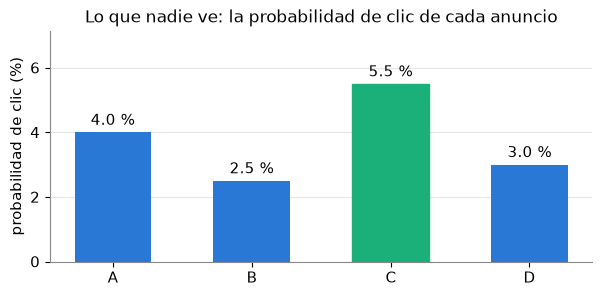

anuncio A: probabilidad de clic 4.0%
anuncio B: probabilidad de clic 2.5%
anuncio C: probabilidad de clic 5.5%
anuncio D: probabilidad de clic 3.0%
el mejor es C (5.5%); la diferencia con el segundo, 1.5%


In [4]:
ANUNCIOS = ["A", "B", "C", "D"]
CTR = np.array([0.040, 0.025, 0.055, 0.030])     # el mejor es C, pero nadie lo sabe
mostrar_anuncios(CTR, ANUNCIOS)
for nombre, p in zip(ANUNCIOS, CTR):
    print(f"anuncio {nombre}: probabilidad de clic {p:.1%}")
print(f"el mejor es {ANUNCIOS[int(CTR.argmax())]} ({CTR.max():.1%}); la diferencia con el segundo, {np.sort(CTR)[-1] - np.sort(CTR)[-2]:.1%}")

### Paso 2 — Probar parejo: ¿cuántas impresiones hacen falta?

La manera más directa de averiguarlo: mostrar cada anuncio la misma cantidad de veces y contar los clics. Cada barra es la tasa observada y la rayita vertical, su intervalo del 95 % (con $n$ impresiones, el ancho se achica como $1/\sqrt{n}$); la raya naranja es la probabilidad verdadera. Probamos con 50, 500 y 5000 impresiones por anuncio.

n =    50:  A    2 clics = 4.0% (entre 1.1% y 13.5%)   B    0 clics = 0.0% (entre 0.0% y 7.1%)   C    0 clics = 0.0% (entre 0.0% y 7.1%)   D    0 clics = 0.0% (entre 0.0% y 7.1%)
n =   500:  A   24 clics = 4.8% (entre 3.2% y 7.0%)   B   17 clics = 3.4% (entre 2.1% y 5.4%)   C   29 clics = 5.8% (entre 4.1% y 8.2%)   D   17 clics = 3.4% (entre 2.1% y 5.4%)
n =  5000:  A  198 clics = 4.0% (entre 3.5% y 4.5%)   B  135 clics = 2.7% (entre 2.3% y 3.2%)   C  290 clics = 5.8% (entre 5.2% y 6.5%)   D  146 clics = 2.9% (entre 2.5% y 3.4%)


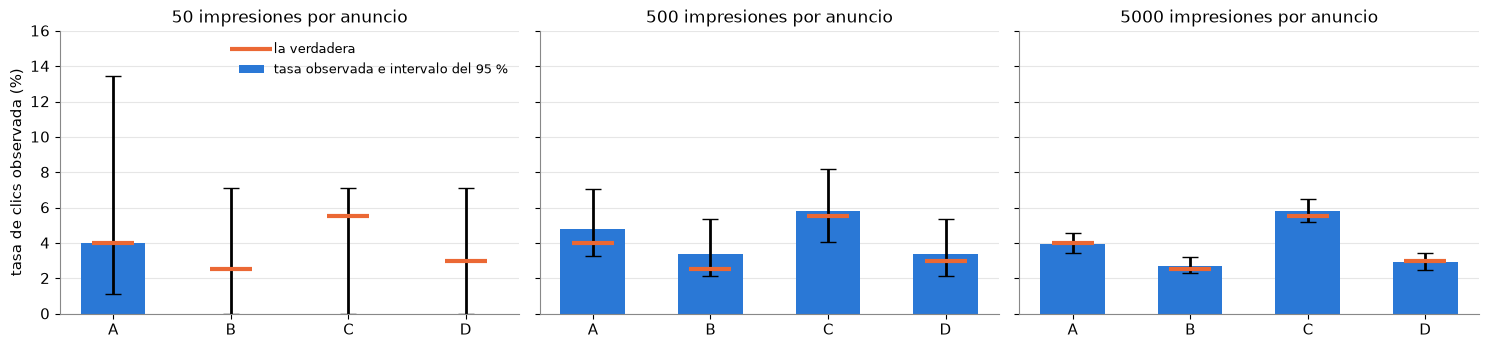

In [5]:
rng = np.random.default_rng(SEMILLA)
fig, axs = plt.subplots(1, 3, figsize=(15, 3.6), sharey=True)
for ax, n in zip(axs, [50, 500, 5000]):
    clics, p, lo, hi = probar_parejo(CTR, n, rng)
    ax.bar(ANUNCIOS, p * 100, yerr=[(p - lo) * 100, (hi - p) * 100], capsize=6, color=COLORES[0], width=0.55,
           label="tasa observada e intervalo del 95 %")
    ax.plot(ANUNCIOS, CTR * 100, "_", color=COLORES[1], ms=30, mew=3, label="la verdadera")
    ax.set_title(f"{n} impresiones por anuncio"); ax.grid(axis="x", visible=False); ax.set_ylim(0, 16)
    print(f"n = {n:5d}:  " + "   ".join(f"{a} {c:4d} clics = {pp:.1%} (entre {l:.1%} y {h:.1%})"
                                         for a, c, pp, l, h in zip(ANUNCIOS, clics, p, lo, hi)))
axs[0].set_ylabel("tasa de clics observada (%)"); axs[0].legend(frameon=False, loc="upper right", fontsize=9)
plt.tight_layout(); plt.show()

Con 50 impresiones por anuncio, los intervalos se pisan: en esta tirada solo A consiguió clics (2) y C, el mejor, ninguno. Con 500, C ya va arriba pero su intervalo todavía se superpone con los demás. Con 5000, C se despega. Las diferencias son de 1 o 2 clics cada 100 impresiones, así que **distinguir cuesta miles de impresiones**, y cada una que va a un anuncio peor es, en promedio, un clic que se pierde. ¿Hay que pagar todo eso?

## 2. Cuánto se pierde por probar: el arrepentimiento

El **arrepentimiento** (*regret*) mide lo que se pierde frente a haber mostrado siempre el mejor anuncio. Si $\mu^*$ es la probabilidad de clic del mejor y $\mu_{a_t}$ la del que se mostró en la impresión $t$:

$$\text{regret}_T = \sum_{t=1}^{T} \big(\mu^* - \mu_{a_t}\big)$$

Es una cuenta en clics esperados: mostrar A en vez de C cuesta $0{,}055 - 0{,}040 = 0{,}015$ clics por impresión. Comparamos tres maneras de repartir 20 000 impresiones:

1. **A/B fijo**: 500 impresiones de cada anuncio (2000 en total) y después, para siempre, el que tuvo más clics. Es la prueba A/B de toda la vida.
2. **$\varepsilon$-greedy** (clase 6) con $\varepsilon = 0{,}1$: el 90 % de las veces el mejor hasta ahora; el 10 %, uno al azar.
3. **UCB**: el de mayor promedio más una bonificación que es grande si se probó poco (la sección 3 la abre).

### Paso 1 — 200 campañas de 20 000 impresiones

Cada método juega 200 campañas independientes (cada una es una semilla distinta). La línea es el promedio y la banda va del 10 % al 90 % de las campañas.

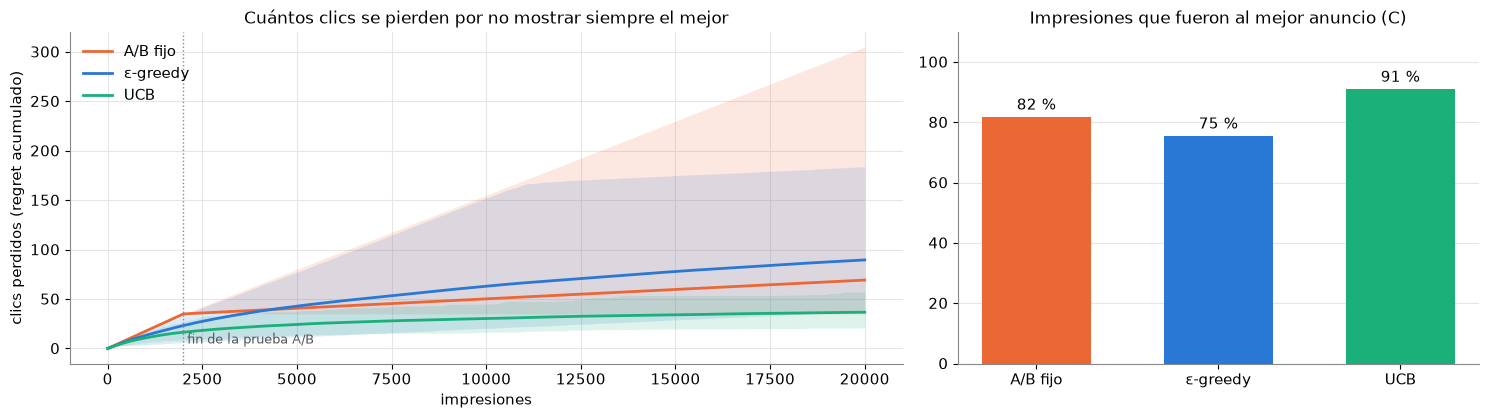

Regret acumulado a las 20000 impresiones (200 campañas):
   A/B fijo  promedio   69.2 clics   (10 % de las campañas:  35.0; 90 %: 305.0)   a las 2000:  35.0   impresiones al mejor: 81.7%
   ε-greedy  promedio   89.6 clics   (10 % de las campañas:  38.1; 90 %: 183.8)   a las 2000:  23.2   impresiones al mejor: 75.4%
   UCB       promedio   36.7 clics   (10 % de las campañas:  20.8; 90 %:  58.0)   a las 2000:  16.4   impresiones al mejor: 90.9%

A/B fijo: anuncio elegido al terminar la prueba, en las 200 campañas: A 11%, B 0%, C 88%, D 1%
Para comparar: mostrar los cuatro por turno, siempre, perdería 350 clics.


In [6]:
T = 20_000
METODOS = ["A/B fijo", "ε-greedy", "UCB"]
C_UCB = 0.2
res_b = {m: correr_bandit(m, CTR, T=T, n_campanas=200, seed=SEMILLA, eps=0.1, c=C_UCB) for m in METODOS}

fig, axs = plt.subplots(1, 2, figsize=(15, 4.3), gridspec_kw={"width_ratios": [1.6, 1]})
t_ = np.arange(1, T + 1)
for m in METODOS:
    reg = res_b[m]["regret"]
    axs[0].plot(t_, reg.mean(0), color=COLOR_MET[m], label=m)
    axs[0].fill_between(t_, np.percentile(reg, 10, 0), np.percentile(reg, 90, 0), color=COLOR_MET[m], alpha=0.15, lw=0)
axs[0].axvline(2000, color="#888888", ls=":", lw=1); axs[0].text(2100, 5, "fin de la prueba A/B", fontsize=9, color="#555555")
axs[0].set_xlabel("impresiones"); axs[0].set_ylabel("clics perdidos (regret acumulado)")
axs[0].set_title("Cuántos clics se pierden por no mostrar siempre el mejor"); axs[0].legend(frameon=False, loc="upper left")
vals = [100 * res_b[m]["al_mejor"].mean() for m in METODOS]
bars = axs[1].bar(METODOS, vals, color=[COLOR_MET[m] for m in METODOS], width=0.6)
axs[1].bar_label(bars, fmt="%.0f %%", padding=3); axs[1].set_ylim(0, 110); axs[1].grid(axis="x", visible=False)
axs[1].set_title("Impresiones que fueron al mejor anuncio (C)")
plt.tight_layout(); plt.show()

print(f"Regret acumulado a las {T} impresiones (200 campañas):")
for m in METODOS:
    reg = res_b[m]["regret"]
    print(f"   {m:9s} promedio {reg[:, -1].mean():6.1f} clics   (10 % de las campañas: {np.percentile(reg[:, -1], 10):5.1f}; "
          f"90 %: {np.percentile(reg[:, -1], 90):5.1f})   a las 2000: {reg[:, 1999].mean():5.1f}   "
          f"impresiones al mejor: {res_b[m]['al_mejor'].mean():.1%}")
fijo = res_b["A/B fijo"]["fijo"]
print("\nA/B fijo: anuncio elegido al terminar la prueba, en las 200 campañas: "
      + ", ".join(f"{a} {np.mean(fijo == i):.0%}" for i, a in enumerate(ANUNCIOS)))
print(f"Para comparar: mostrar los cuatro por turno, siempre, perdería {T * (CTR.max() - CTR.mean()):.0f} clics.")

Cómo leer la figura:

- **A/B fijo** pierde clics a ritmo constante durante la prueba (tres de cada cuatro impresiones van a un anuncio peor): 35 clics en las primeras 2000. Después la curva se aplana... en las campañas que eligieron bien (el 88 %). El 12 % que eligió A o D sigue perdiendo para siempre: por eso la banda se abre hacia arriba.
- **$\varepsilon$-greedy** nunca deja de probar: su curva sigue subiendo porque el 10 % de las impresiones va siempre al azar, aunque ya sepa cuál es el mejor. A las 20 000 es el que más perdió (89,6 clics de promedio).
- **UCB** prueba mucho al principio y cada vez menos: su curva se dobla. Al final es la que menos perdió (36,7 clics, la mitad que A/B fijo) y la que más impresiones le dio a C (91 %).

### Paso 2 — Cómo crece cada curva

La diferencia de fondo está en la **forma** de la curva, no en el número final. Miramos el regret de cada tramo de 2000 impresiones: un método que dejó de probar pierde cada vez menos por tramo.

A/B fijo  clics perdidos por tramo de 2000:  35.0    3.8    3.8    3.8    3.8    3.8    3.8    3.8    3.8    3.8
ε-greedy  clics perdidos por tramo de 2000:  23.2   14.4    9.7    8.1    7.6    6.3    5.8    5.3    4.9    4.3
UCB       clics perdidos por tramo de 2000:  16.4    6.0    3.7    2.4    1.8    1.9    1.3    1.2    1.1    1.0

piso de ε-greedy: aunque ya sepa cuál es el mejor, el 10 % al azar cuesta 2000 · 0.1 · 0.0175 = 3.5 clics por tramo


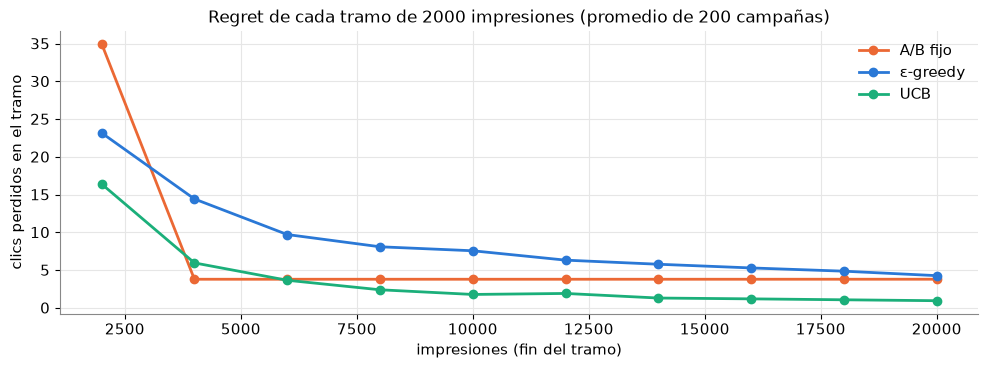

In [7]:
fig, ax = plt.subplots(figsize=(10, 3.8))
bordes = np.arange(0, T + 1, 2000)
for m in METODOS:
    reg = res_b[m]["regret"].mean(0)
    por_tramo = np.diff(np.concatenate([[0], reg[bordes[1:] - 1]]))
    ax.plot(bordes[1:], por_tramo, "o-", color=COLOR_MET[m], label=m)
    print(f"{m:9s} clics perdidos por tramo de 2000: " + "  ".join(f"{x:5.1f}" for x in por_tramo))
piso = 2000 * 0.1 * np.mean(CTR.max() - CTR)
print(f"\npiso de ε-greedy: aunque ya sepa cuál es el mejor, el 10 % al azar cuesta 2000 · 0.1 · {np.mean(CTR.max() - CTR):.4f} = {piso:.1f} clics por tramo")
ax.set_xlabel("impresiones (fin del tramo)"); ax.set_ylabel("clics perdidos en el tramo")
ax.set_title("Regret de cada tramo de 2000 impresiones (promedio de 200 campañas)"); ax.legend(frameon=False)
plt.tight_layout(); plt.show()

$\varepsilon$-greedy pierde cada vez menos, pero hacia un piso de 3,5 clics por tramo que no se va nunca: es el precio fijo de su 10 % al azar. UCB baja sin piso, de 16,4 a 1,0 clics por tramo: prueba solo lo que todavía está en duda. A/B fijo, después de la prueba, pierde 3,8 por tramo, todo por las campañas que eligieron mal, y esas no se corrigen nunca. Para estos números no hace falta ninguna cota: alcanza con ver que la curva de UCB se aplana y la de $\varepsilon$-greedy no.

## 3. UCB y la bonificación: optimismo ante la incertidumbre

UCB (*upper confidence bound*, cota superior de confianza) elige en cada impresión el anuncio con el mayor

$$\text{puntaje}(a) = \underbrace{\hat\mu_a}_{\text{promedio de clics}} + \underbrace{c\,\sqrt{\frac{\ln t}{n_a}}}_{\text{bonificación}}$$

donde $n_a$ es cuántas veces se mostró el anuncio $a$ y $t$ cuántas impresiones van en total. La bonificación es **grande si $n_a$ es chico**: lo poco probado recibe el beneficio de la duda. Es el **optimismo ante la incertidumbre** (*optimism in the face of uncertainty*): ante la duda, suponer que puede ser bueno, y probarlo. Si no lo era, su $n_a$ crece, la bonificación se achica y deja de elegirse.

Usamos $c = 0{,}2$. El valor de libro es $\sqrt 2 \approx 1{,}41$, pensado para el peor caso de premios entre 0 y 1 (desvío de hasta 0,5); acá los clics son raros y el desvío de un clic con probabilidad 5 % es $\sqrt{0{,}05 \cdot 0{,}95} \approx 0{,}22$, así que la duda se mide en esa escala (en el ejercicio pueden probar $1{,}41$).

### Paso 1 — Las barras de UCB se achican

Una campaña de UCB vista en cuatro momentos. Cada barra va del promedio $\hat\mu_a$ (el punto) al puntaje (la punta de arriba): el largo es la bonificación. La estrella marca el anuncio que UCB elige en ese momento.

t =     20: A: n =     5, prom. 0.000, bonif. 0.155   B: n =     5, prom. 0.000, bonif. 0.155   C: n =     5, prom. 0.000, bonif. 0.155   D: n =     5, prom. 0.000, bonif. 0.155   -> elige A
t =    200: A: n =    79, prom. 0.038, bonif. 0.052   B: n =    65, prom. 0.031, bonif. 0.057   C: n =    28, prom. 0.000, bonif. 0.087   D: n =    28, prom. 0.000, bonif. 0.087   -> elige A
t =   2000: A: n =   279, prom. 0.036, bonif. 0.033   B: n =   159, prom. 0.025, bonif. 0.044   C: n =  1472, prom. 0.060, bonif. 0.014   D: n =    90, prom. 0.011, bonif. 0.058   -> elige C
t =  19999: A: n =  1953, prom. 0.047, bonif. 0.014   B: n =   265, prom. 0.023, bonif. 0.039   C: n = 16673, prom. 0.056, bonif. 0.005   D: n =  1108, prom. 0.042, bonif. 0.019   -> elige C


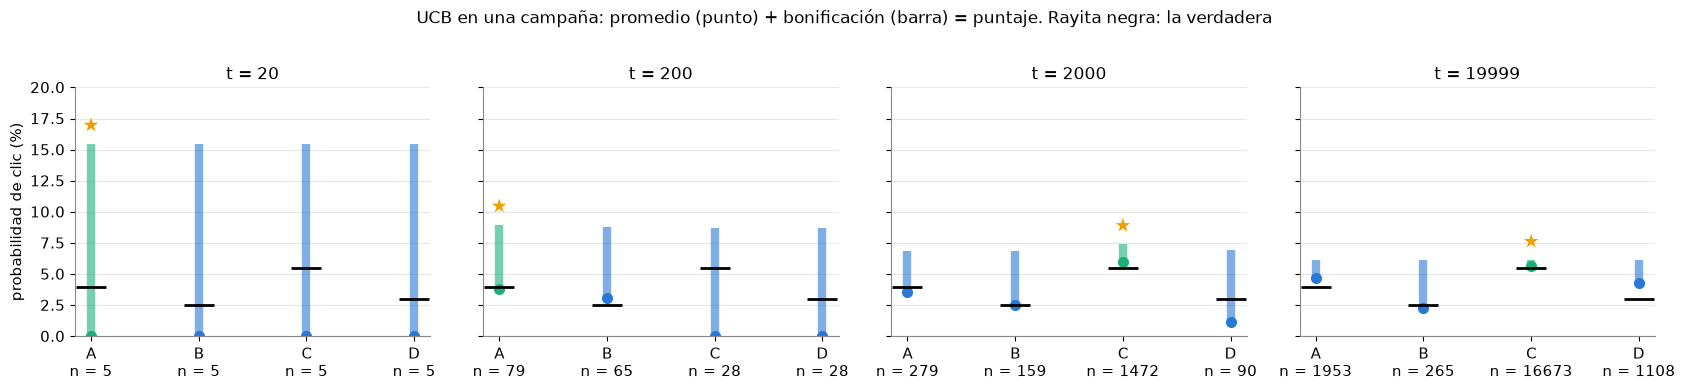


al final de esa campaña: impresiones de cada anuncio = {'A': 1953, 'B': 265, 'C': 16674, 'D': 1108}


In [8]:
MOMENTOS = [20, 200, 2000, 19_999]
una = correr_bandit("UCB", CTR, T=T, n_campanas=1, seed=3, c=C_UCB, guardar=set(MOMENTOS))
fig, axs = plt.subplots(1, 4, figsize=(17, 3.8), sharey=True)
for ax, t in zip(axs, MOMENTOS):
    n_t, cl_t = una["fotos"][t]
    media = cl_t / n_t; bono = C_UCB * np.sqrt(np.log(t) / n_t); punt = media + bono
    elegido = int(punt.argmax())
    for i in range(4):
        col = COLORES[2] if i == elegido else COLORES[0]
        ax.plot([i, i], [media[i] * 100, punt[i] * 100], color=col, lw=6, alpha=0.6, solid_capstyle="butt")
        ax.plot(i, media[i] * 100, "o", color=col, ms=7)
        ax.text(i, punt[i] * 100 + 1, "★" if i == elegido else "", ha="center", fontsize=14, color=COLORES[3])
    ax.plot(range(4), CTR * 100, "_", color="k", ms=22, mew=2)
    ax.set_xticks(range(4)); ax.set_xticklabels([f"{a}\nn = {int(x)}" for a, x in zip(ANUNCIOS, n_t)])
    ax.set_title(f"t = {t}"); ax.grid(axis="x", visible=False)
    print(f"t = {t:6d}: " + "   ".join(f"{a}: n = {int(x):5d}, prom. {m:.3f}, bonif. {b:.3f}" for a, x, m, b in zip(ANUNCIOS, n_t, media, bono))
          + f"   -> elige {ANUNCIOS[elegido]}")
axs[0].set_ylabel("probabilidad de clic (%)"); axs[0].set_ylim(0, 20)
plt.suptitle("UCB en una campaña: promedio (punto) + bonificación (barra) = puntaje. Rayita negra: la verdadera", y=1.02)
plt.tight_layout(); plt.show()
print(f"\nal final de esa campaña: impresiones de cada anuncio = {dict(zip(ANUNCIOS, una['n'][0].astype(int).tolist()))}")

Al principio las barras son enormes y UCB va probando los cuatro. A medida que se muestran, las barras se achican; las de los anuncios peores dejan de achicarse porque casi no se muestran, y C se lleva casi todas las impresiones. Nunca dejan de mostrarse del todo: como $\ln t$ sigue creciendo, la bonificación de un anuncio olvidado vuelve a subir despacio, y de vez en cuando se lo prueba de nuevo.

### Paso 2 — Una cuenta a mano

Tomamos un momento de esa campaña en el que **UCB no elige el de mayor promedio** y hacemos la cuenta anuncio por anuncio.

In [9]:
# buscamos un momento (después de las primeras 300 impresiones) en el que el puntaje y el promedio no coinciden
busca = correr_bandit("UCB", CTR, T=3000, n_campanas=1, seed=3, c=C_UCB, guardar=set(range(300, 3000)))
for t_mano in range(300, 3000):
    n_m, cl_m = busca["fotos"][t_mano]
    if (cl_m / n_m).argmax() != (cl_m / n_m + C_UCB * np.sqrt(np.log(t_mano) / n_m)).argmax():
        break
media_m = cl_m / n_m
bono_m = C_UCB * np.sqrt(np.log(t_mano) / n_m)
print(f"Impresión t = {t_mano},  ln t = {np.log(t_mano):.3f},  c = {C_UCB}")
for i, a in enumerate(ANUNCIOS):
    print(f"   {a}: {int(cl_m[i]):3d} clics en n = {int(n_m[i]):4d}  ->  promedio = {media_m[i]:.4f}   "
          f"bonificación = {C_UCB} · √({np.log(t_mano):.3f} / {int(n_m[i])}) = {bono_m[i]:.4f}   "
          f"puntaje = {media_m[i] + bono_m[i]:.4f}")
print(f"\nmayor promedio: {ANUNCIOS[int(media_m.argmax())]}   mayor puntaje: {ANUNCIOS[int((media_m + bono_m).argmax())]}  <- el que muestra UCB")

Impresión t = 300,  ln t = 5.704,  c = 0.2
   A:   5 clics en n =  125  ->  promedio = 0.0400   bonificación = 0.2 · √(5.704 / 125) = 0.0427   puntaje = 0.0827
   B:   4 clics en n =  108  ->  promedio = 0.0370   bonificación = 0.2 · √(5.704 / 108) = 0.0460   puntaje = 0.0830
   C:   0 clics en n =   34  ->  promedio = 0.0000   bonificación = 0.2 · √(5.704 / 34) = 0.0819   puntaje = 0.0819
   D:   0 clics en n =   33  ->  promedio = 0.0000   bonificación = 0.2 · √(5.704 / 33) = 0.0831   puntaje = 0.0831

mayor promedio: A   mayor puntaje: D  <- el que muestra UCB


El anuncio de mayor promedio (A) no gana: D, con 0 clics en 33 impresiones, tiene la bonificación más grande y su puntaje lo supera por muy poco. (C, el mejor de verdad, también lleva 0 clics en 34 impresiones: mala suerte del comienzo, que la bonificación se encarga de corregir.) UCB lo muestra **no porque crea que es mejor, sino porque todavía no sabe si lo es**. Si en las próximas impresiones no consigue clics, su promedio baja, su $n$ sube y deja de ganar.

> **Thompson, en una línea.** Otra receta muy usada es el muestreo de Thompson (*Thompson sampling*; Russo et al., 2018): para cada anuncio, sortear una probabilidad de clic plausible según lo que se vio hasta ahora y mostrar el que salió más alto. Lo poco probado tiene una creencia ancha y a veces sortea alto, así que también explora donde hay duda: llega a lo mismo que UCB por otro camino, sin elegir $c$.

## 4. De los bandits a la cueva: $\varepsilon$-greedy no llega

En el bandit, cada impresión trae su respuesta al instante. En la cueva el premio está **al final de un camino**: hasta que el agente llega una vez a la salida, todas las recompensas son 0 (la recompensa escasa de la clase 2), su $Q$ sigue en 0 y «la mejor acción» no significa nada. **Sin recompensa, $\varepsilon$-greedy es una caminata al azar con costumbres.**

En la cueva de siempre eso alcanzaba: el azar llega a la salida de vez en cuando (en la clase 6 todas las semillas con $\varepsilon \geq 0{,}05$ la encontraron). Para ver el problema usamos una **cueva grande**, un laberinto con muchos callejones sin salida.

### Paso 1 — La cueva grande

casillas libres: 155   camino más corto de S a la salida: 44 pasos   partidas de hasta 300 pasos
casillas a más de 30 pasos de S: 106


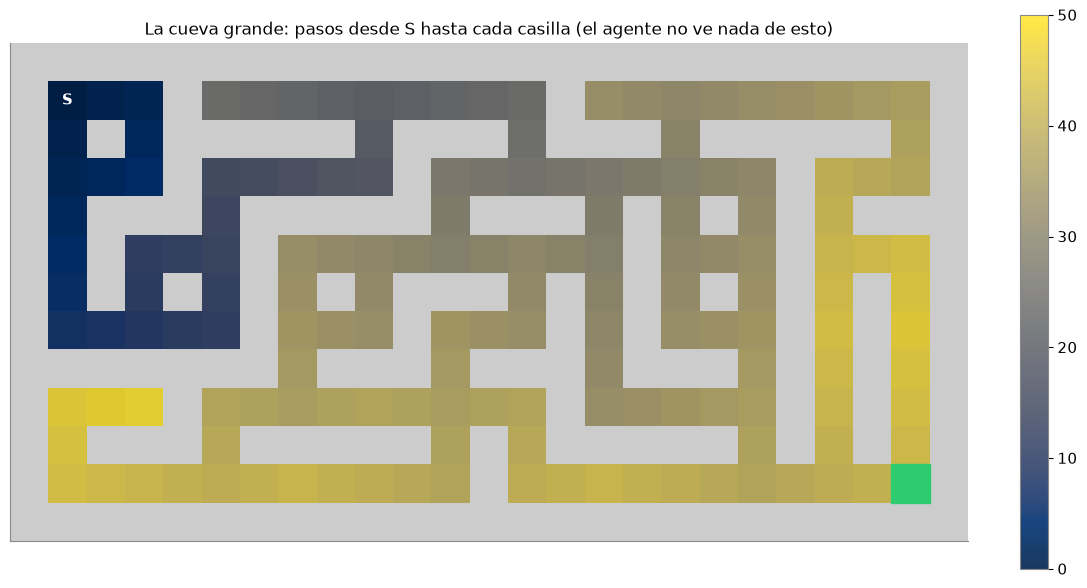

In [10]:
env = CaveEnv(cave_map=CUEVA_GRANDE, max_steps=300)
dist = distancias(env)
print(f"casillas libres: {env.nS}   camino más corto de S a la salida: {dist[env.goal]} pasos   partidas de hasta {env.max_steps} pasos")
print(f"casillas a más de 30 pasos de S: {sum(d > 30 for d in dist.values())}")
fig, ax = plt.subplots(figsize=(11, 6))
env.plot(values=np.array([dist[s] for s in range(env.nS)], float), ax=ax, cmap="cividis",
         title="La cueva grande: pasos desde S hasta cada casilla (el agente no ve nada de esto)")
plt.tight_layout(); plt.show()

### Paso 2 — La carrera, con el mismo presupuesto

Todos los exploradores de hoy reciben **el mismo presupuesto: 30 000 pasos** (100 partidas de 300 pasos). Empezamos por el dado puro ($\varepsilon = 1$) y por Q-learning con $\varepsilon$-greedy como en la clase 6 ($\alpha = 0{,}2$, $\gamma = 0{,}99$, $Q$ arranca en 0 más un ruido minúsculo), con $\varepsilon = 0{,}1$ y $0{,}3$. Para cada uno, 20 semillas. Medimos en cuántas llega a la salida al menos una vez, cuántos pasos tarda en llegar la primera vez y cuántas casillas distintas pisa.

Presupuesto: 30.000 pasos, 20 semillas. Camino más corto: 44 pasos; casillas: 155
al azar (ε = 1)            llegó en  0 de 20 semillas (  0%)   pasos hasta la 1.ª salida (mediana)         —   casillas visitadas  54.3   partidas que salen (últimas 20)   0%
ε-greedy (ε = 0,1)         llegó en  1 de 20 semillas (  5%)   pasos hasta la 1.ª salida (mediana)    26.687   casillas visitadas  63.4   partidas que salen (últimas 20)   2%
ε-greedy (ε = 0,3)         llegó en  1 de 20 semillas (  5%)   pasos hasta la 1.ª salida (mediana)    25.713   casillas visitadas 100.3   partidas que salen (últimas 20)   2%


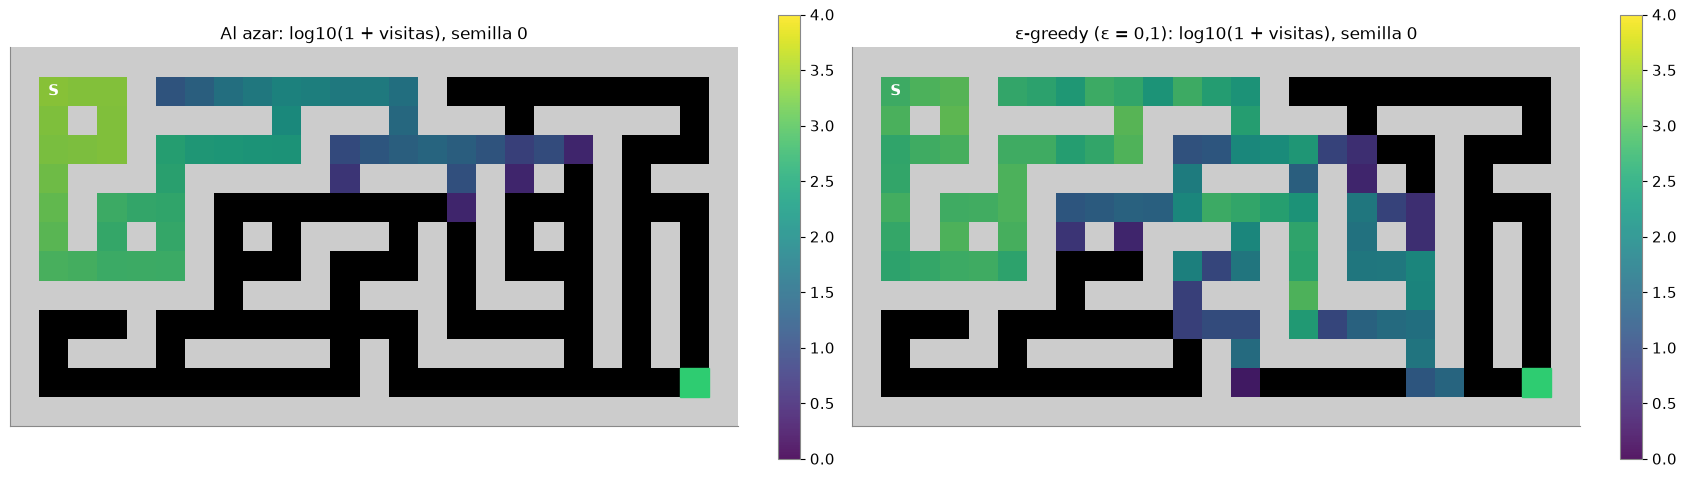

al azar (ε = 1), semilla 0: casillas pisadas 51 de 155; casillas a más de 30 pasos de S pisadas: 3
ε-greedy (ε = 0,1), semilla 0: casillas pisadas 89 de 155; casillas a más de 30 pasos de S pisadas: 40


In [11]:
PRESUPUESTO = 30_000
SEMILLAS = range(20)
carrera = {}
carrera["al azar (ε = 1)"] = [caminar_al_azar(env, PRESUPUESTO, s) for s in SEMILLAS]
carrera["ε-greedy (ε = 0,1)"] = [explorar(env, PRESUPUESTO, s, eps=0.1) for s in SEMILLAS]
carrera["ε-greedy (ε = 0,3)"] = [explorar(env, PRESUPUESTO, s, eps=0.3) for s in SEMILLAS]
resumen = {}
print(f"Presupuesto: {miles(PRESUPUESTO)} pasos, 20 semillas. Camino más corto: {dist[env.goal]} pasos; casillas: {env.nS}")
for nombre, res in carrera.items():
    resumen[nombre] = resumir(nombre, res, PRESUPUESTO)

fig, axs = plt.subplots(1, 2, figsize=(17, 4.8))
mapa_visitas(env, carrera["al azar (ε = 1)"][0]["N"], axs[0], "Al azar: log10(1 + visitas), semilla 0")
mapa_visitas(env, carrera["ε-greedy (ε = 0,1)"][0]["N"], axs[1], "ε-greedy (ε = 0,1): log10(1 + visitas), semilla 0")
plt.tight_layout(); plt.show()
for nombre in ["al azar (ε = 1)", "ε-greedy (ε = 0,1)"]:
    r0 = carrera[nombre][0]
    print(f"{nombre}, semilla 0: casillas pisadas {int(np.sum(r0['N'] > 0))} de {env.nS}; "
          f"casillas a más de 30 pasos de S pisadas: {sum(1 for s in range(env.nS) if dist[s] > 30 and r0['N'][s] > 0)}")

El dado puro no llega nunca: arranca cada partida en S y en 300 pasos al azar no se aleja lo suficiente (las visitas se apagan con la distancia; negro = nunca pisada). Q-learning con $\varepsilon$-greedy llega un poco más lejos, porque el ruido inicial de $Q$ se va gastando en las flechas ya usadas y eso, sin querer, empuja a probar las otras; pero con este presupuesto solo 1 de las 20 semillas encuentra la salida, con $\varepsilon = 0{,}1$ y también con $0{,}3$ (que pisa más casillas, 100 de 155 en promedio, pero tampoco llega). El problema no es el valor de $\varepsilon$: es que **probar al azar no tiene dirección**. El agente no distingue «acá ya estuve mil veces» de «acá nunca vine».

## 5. Optimismo en la cueva: ir adonde menos se estuvo

La idea de UCB, llevada a la cueva: que lo poco probado **parezca bueno** hasta que se demuestre lo contrario. Dos maneras de hacerlo con la misma tabla $Q$:

1. **Valores iniciales optimistas** (Sutton y Barto, 2.6): $Q$ arranca en 1, el máximo que se puede cobrar, en vez de 0. Cada vez que el agente prueba una flecha y no encuentra nada, su valor baja; las flechas nunca probadas siguen prometiendo 1, así que las va probando todas.
2. **Bonificación por conteo** (*count-based bonus*; Bellemare et al., 2016): llevar la cuenta $N(s)$ de las visitas a cada casilla y pagarse un premio extra por pisar una casilla poco visitada,

$$r_{\text{total}} = r + \frac{\beta}{\sqrt{N(s')}}$$

### Paso 1 — Tres exploradores nuevos, mismo presupuesto

Mismo Q-learning, mismo presupuesto de 30 000 pasos, mismas 20 semillas, $\varepsilon = 0{,}1$. Cambia solo cómo arranca $Q$ y qué recompensa recibe: optimista ($Q_0 = 1$), conteo solo ($\beta = 0{,}01$, $Q_0 = 0$) y los dos juntos.

In [12]:
BETA = 0.01
carrera["optimista (Q0 = 1)"] = [explorar(env, PRESUPUESTO, s, eps=0.1, q0=1.0) for s in SEMILLAS]
carrera["conteo solo (β = 0,01)"] = [explorar(env, PRESUPUESTO, s, eps=0.1, beta=BETA) for s in SEMILLAS]
carrera["optimista + conteo"] = [explorar(env, PRESUPUESTO, s, eps=0.1, q0=1.0, beta=BETA) for s in SEMILLAS]
print(f"Presupuesto: {miles(PRESUPUESTO)} pasos, 20 semillas")
for nombre, res in carrera.items():
    resumen[nombre] = resumir(nombre, res, PRESUPUESTO)
for nombre in ["optimista (Q0 = 1)", "optimista + conteo"]:
    print(f"{nombre}: semillas que llegan en la primera partida (antes del paso 300): "
          f"{sum(1 for r in carrera[nombre] if r['primera'] and r['primera'] <= 300)} de 20")

Presupuesto: 30.000 pasos, 20 semillas
al azar (ε = 1)            llegó en  0 de 20 semillas (  0%)   pasos hasta la 1.ª salida (mediana)         —   casillas visitadas  54.3   partidas que salen (últimas 20)   0%
ε-greedy (ε = 0,1)         llegó en  1 de 20 semillas (  5%)   pasos hasta la 1.ª salida (mediana)    26.687   casillas visitadas  63.4   partidas que salen (últimas 20)   2%
ε-greedy (ε = 0,3)         llegó en  1 de 20 semillas (  5%)   pasos hasta la 1.ª salida (mediana)    25.713   casillas visitadas 100.3   partidas que salen (últimas 20)   2%
optimista (Q0 = 1)         llegó en 20 de 20 semillas (100%)   pasos hasta la 1.ª salida (mediana)     8.666   casillas visitadas 155.0   partidas que salen (últimas 20)  72%
conteo solo (β = 0,01)     llegó en  0 de 20 semillas (  0%)   pasos hasta la 1.ª salida (mediana)         —   casillas visitadas  26.4   partidas que salen (últimas 20)   0%
optimista + conteo         llegó en 20 de 20 semillas (100%)   pasos hasta la 1.ª sali

### Paso 2 — El mapa de visitas

La semilla 0 de cada explorador: cuántas veces pisó cada casilla en los 30 000 pasos (negro = nunca).

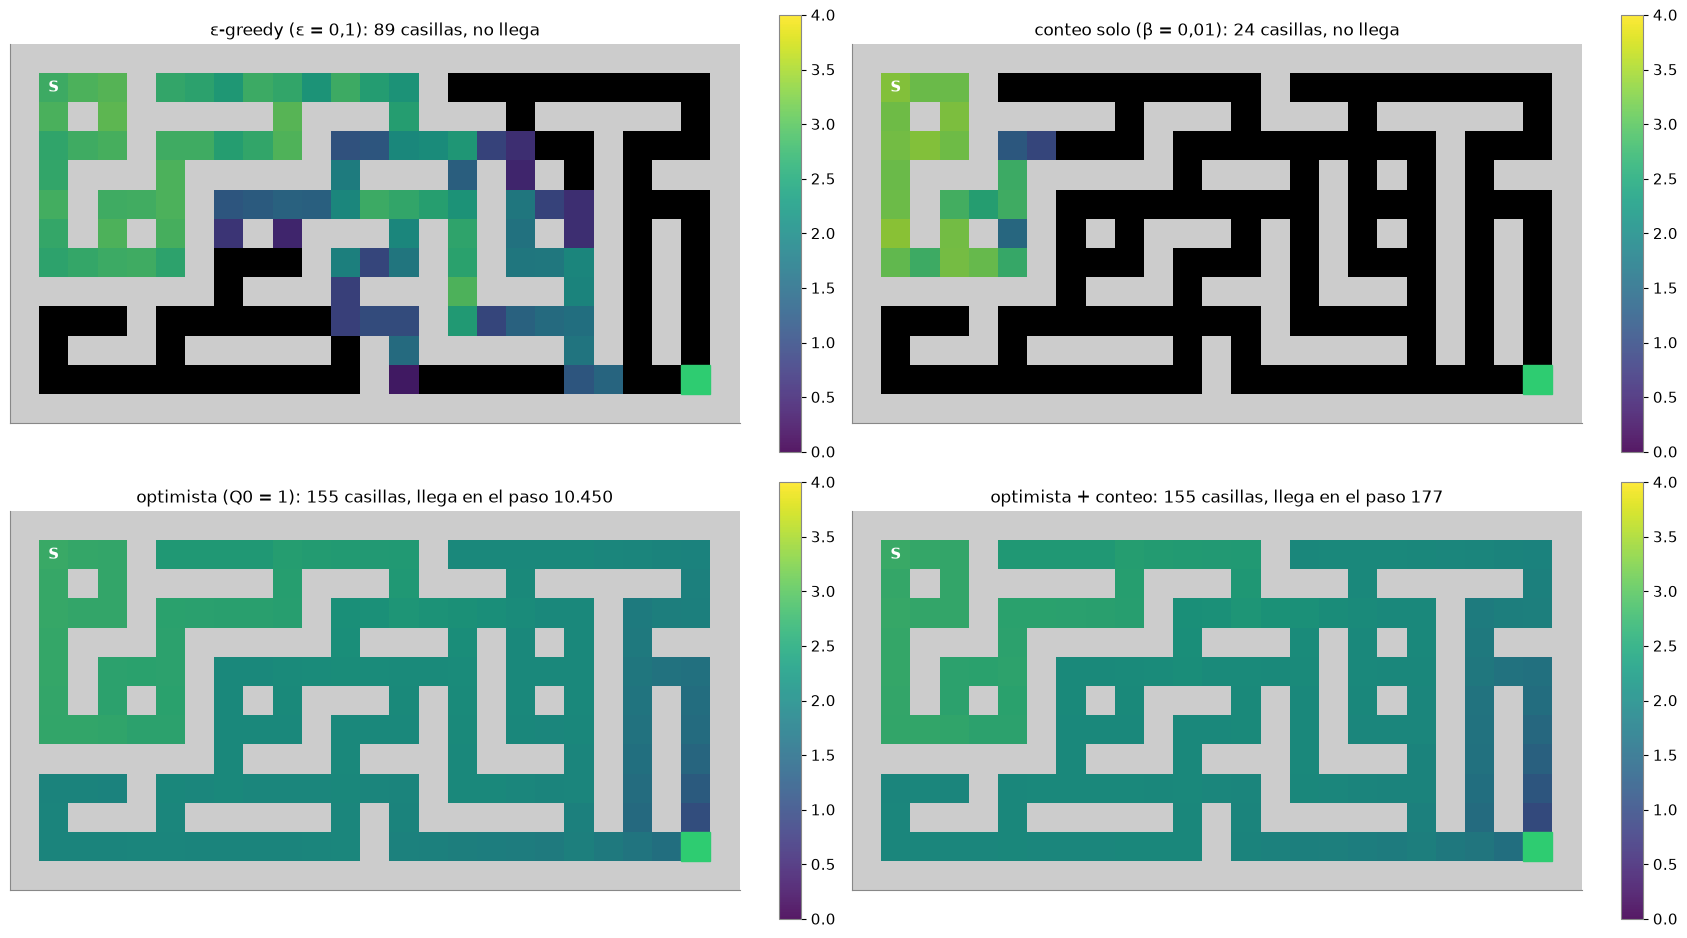

In [13]:
fig, axs = plt.subplots(2, 2, figsize=(17, 9.5))
for ax, nombre in zip(axs.ravel(), ["ε-greedy (ε = 0,1)", "conteo solo (β = 0,01)", "optimista (Q0 = 1)", "optimista + conteo"]):
    r0 = carrera[nombre][0]
    llega = f"llega en el paso {miles(r0['primera'])}" if r0["primera"] else "no llega"
    mapa_visitas(env, r0["N"], ax, f"{nombre}: {int(np.sum(r0['N'] > 0))} casillas, {llega}")
plt.tight_layout(); plt.show()

El optimismo cambia todo: los exploradores optimistas pisan **las 155 casillas** de la cueva y llegan a la salida en las 20 semillas, con una fracción del presupuesto (mediana de 8666 pasos el optimista solo). Después de encontrarla, la mayoría de sus partidas salen (el 72 % de las últimas 20, con $\varepsilon = 0{,}1$ que sigue probando): lo que encontraron, lo aprovechan.

El conteo solo, en cambio, **empeora** las cosas, y vale la pena entender por qué. La bonificación también paga por volver a una casilla conocida (cada vez menos, pero algo). Y en una tabla, una flecha que nunca se probó vale 0: menos que cualquier camino conocido, que ya acumuló bonificaciones. El agente aprende a dar vueltas por lo que ya conoce. La bonificación solo empuja hacia lo nuevo si **lo nunca probado vale al menos tanto como lo ya visto**, y eso es otra vez optimismo: junto con $Q_0 = 1$, el conteo es el explorador más rápido de la carrera (mediana de 5218 pasos, y en 7 de las 20 semillas llega en la primera partida, antes del paso 300; el optimista solo, en ninguna). (Con redes neuronales, como en Bellemare et al., lo nuevo no vale 0 de entrada.)

### Paso 3 — La carrera completa

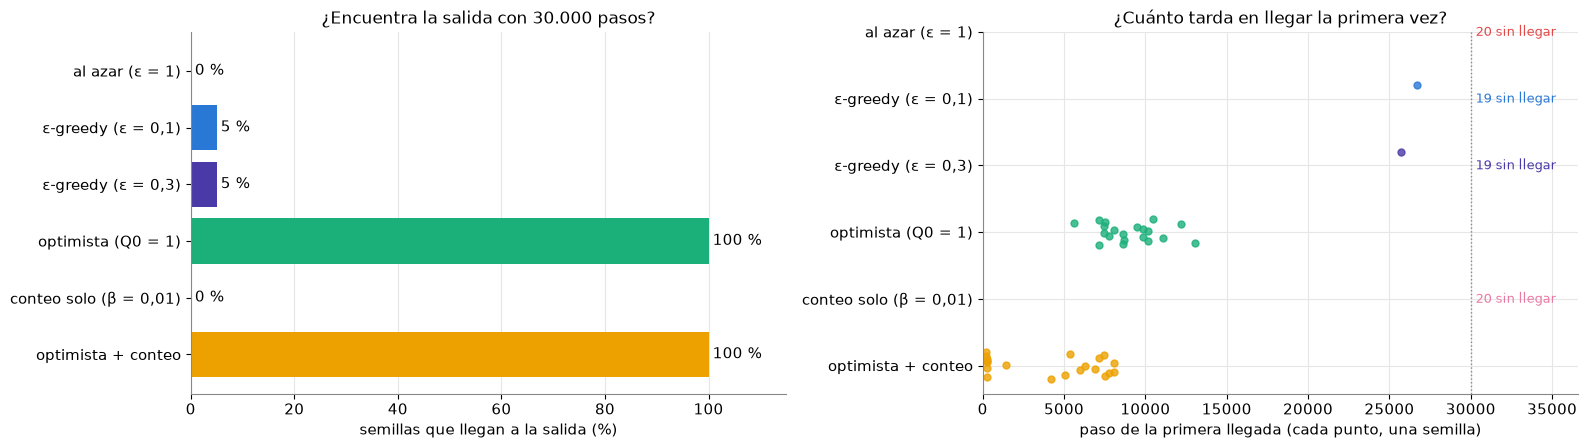

al azar (ε = 1)            éxito   0%   mediana de la 1.ª llegada      —   casillas visitadas  54.3 de 155
ε-greedy (ε = 0,1)         éxito   5%   mediana de la 1.ª llegada  26687   casillas visitadas  63.4 de 155
ε-greedy (ε = 0,3)         éxito   5%   mediana de la 1.ª llegada  25713   casillas visitadas 100.3 de 155
optimista (Q0 = 1)         éxito 100%   mediana de la 1.ª llegada   8666   casillas visitadas 155.0 de 155
conteo solo (β = 0,01)     éxito   0%   mediana de la 1.ª llegada      —   casillas visitadas  26.4 de 155
optimista + conteo         éxito 100%   mediana de la 1.ª llegada   5218   casillas visitadas 155.0 de 155


In [14]:
nombres = list(carrera)
fig, axs = plt.subplots(1, 2, figsize=(16, 4.6))
cols = [COLORES[7], COLORES[0], COLORES[6], COLORES[2], COLORES[4], COLORES[3]]
exito = [100 * resumen[n]["exito"] for n in nombres]
bars = axs[0].barh(nombres, exito, color=cols); axs[0].bar_label(bars, fmt="%.0f %%", padding=3)
axs[0].set_xlim(0, 115); axs[0].invert_yaxis(); axs[0].set_xlabel("semillas que llegan a la salida (%)")
axs[0].set_title(f"¿Encuentra la salida con {miles(PRESUPUESTO)} pasos?"); axs[0].grid(axis="y", visible=False)
for i, n in enumerate(nombres):
    prim = [r["primera"] for r in carrera[n] if r["primera"]]
    axs[1].plot(prim, np.full(len(prim), i) + np.linspace(-0.2, 0.2, len(prim)), "o", color=cols[i], ms=5, alpha=0.8)
    if len(prim) < len(carrera[n]):
        axs[1].text(PRESUPUESTO * 1.01, i, f"{len(carrera[n]) - len(prim)} sin llegar", va="center", fontsize=9, color=cols[i])
axs[1].set_yticks(range(len(nombres))); axs[1].set_yticklabels(nombres); axs[1].invert_yaxis()
axs[1].set_xlim(0, PRESUPUESTO * 1.22); axs[1].axvline(PRESUPUESTO, color="#888888", ls=":", lw=1)
axs[1].set_xlabel("paso de la primera llegada (cada punto, una semilla)"); axs[1].set_title("¿Cuánto tarda en llegar la primera vez?")
plt.tight_layout(); plt.show()
for n in nombres:
    m = resumen[n]["mediana"]
    print(f"{n:26s} éxito {resumen[n]['exito']:4.0%}   mediana de la 1.ª llegada {('%.0f' % m) if m else '—':>6s}   casillas visitadas {resumen[n]['casillas']:5.1f} de {env.nS}")

## 6. Go-Explore: primero volver, después explorar

El optimismo funcionó porque hay una tabla con una fila por casilla. En un juego como *Montezuma's Revenge* de Atari, donde durante años los agentes sacaban 0 puntos, no hay tabla posible, y los métodos de curiosidad fallaban por dos razones (Ecoffet et al., 2021): se **desapegaban** (*detachment*) de las fronteras prometedoras que ya habían dejado atrás, y al intentar volver con una política que explora se **descarrilaban** (*derailment*) antes de llegar.

**Go-Explore** separa las dos cosas: *first return, then explore*.

1. Guardar un **archivo** de **celdas** visitadas (acá, cada casilla es una celda), con la secuencia de acciones más corta que llevó a cada una.
2. **Elegir** una celda, más seguido cuanto menos vista (peso $1/\sqrt{\text{vistas}+1}$).
3. **Volver** a ella **sin explorar**: restaurando el estado del simulador (`env.s = celda`) o repitiendo desde S la secuencia guardada.
4. **Explorar** desde ahí 30 pasos al azar.
5. **Actualizar** el archivo: celdas nuevas, secuencias más cortas. Nada se olvida.

No hay tabla $Q$ ni bonificación: solo memoria y la posibilidad de volver.

### Paso 1 — Una iteración

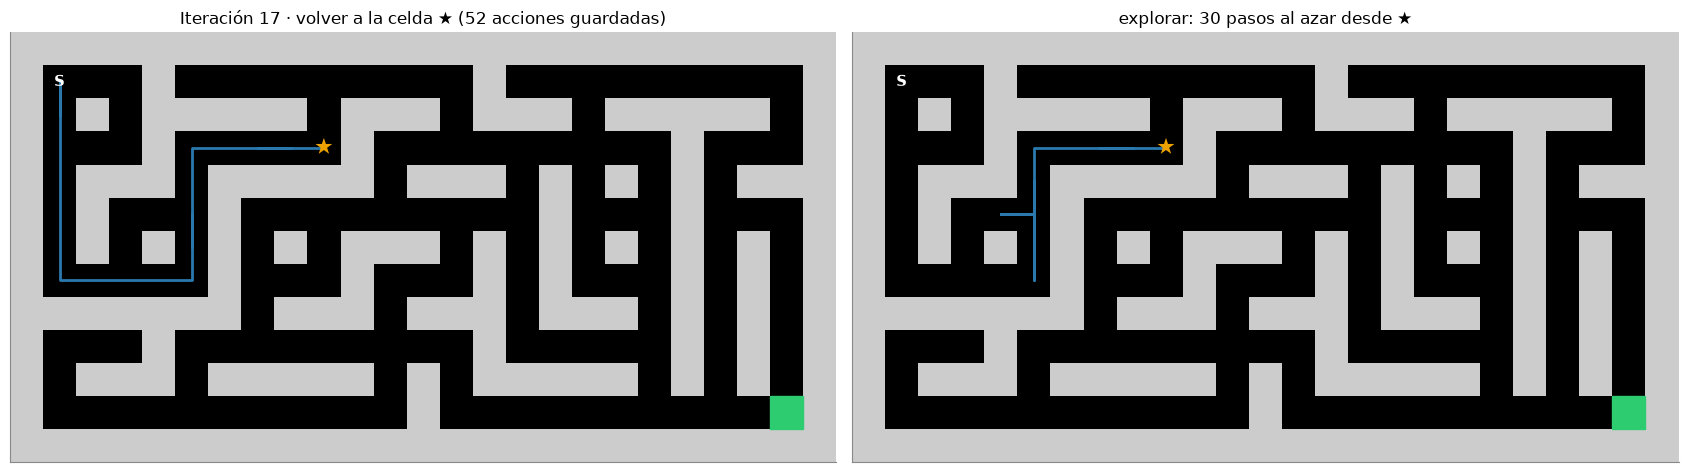

iteración 17: la celda elegida está a 18 pasos de S; la secuencia guardada para volver tiene 52 acciones; explorando pisó 10 casillas distintas


In [15]:
env_ge = CaveEnv(cave_map=CUEVA_GRANDE, max_steps=10**9)     # sin límite por partida: el límite es el presupuesto
ge = go_explore(env_ge, PRESUPUESTO, semilla=0, volver="restaurar", fotos=(5, 20, 60))
ej = ge["ejemplo"]
fig, axs = plt.subplots(1, 2, figsize=(17, 4.8))
env_ge.plot(path=recorrer(env_ge, ej["acc"]), ax=axs[0], title=f"Iteración {ej['iteracion']} · volver a la celda ★ ({len(ej['acc'])} acciones guardadas)")
env_ge.plot(path=ej["explorar"], ax=axs[1], title="explorar: 30 pasos al azar desde ★")
for ax in axs:
    marcar(env_ge, ax, ej["celda"])
plt.tight_layout(); plt.show()
print(f"iteración {ej['iteracion']}: la celda elegida está a {dist[ej['celda']]} pasos de S; la secuencia guardada para volver tiene "
      f"{len(ej['acc'])} acciones; explorando pisó {len(set(ej['explorar']))} casillas distintas")

### Paso 2 — Cómo crece el archivo

El color de cada casilla dice **en qué iteración entró al archivo** (oscuro = temprano). Volvemos restaurando el estado.

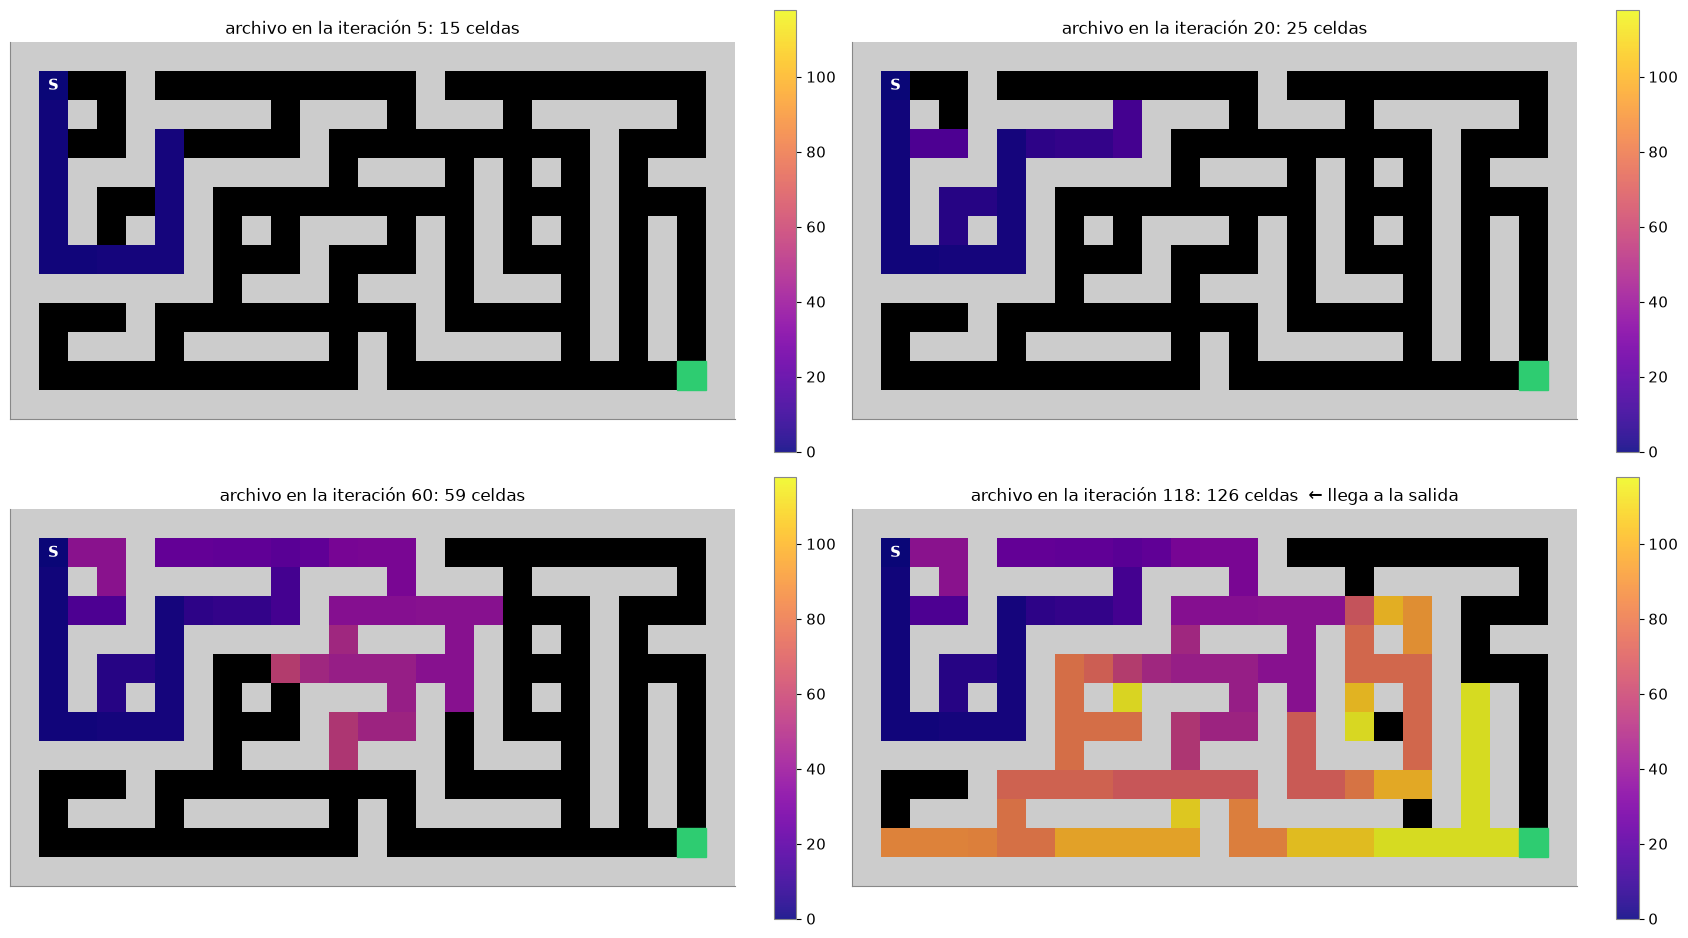

semilla 0: llega a la salida en la iteración 118, después de 3.515 pasos; archivo final: 126 de 155 casillas


In [16]:
h = ge["hallazgo"]
fotos = dict(sorted(ge["fotos"].items()))
claves = [k for k in fotos if k in (5, 20, 60)] + [h["iteracion"]]
fig, axs = plt.subplots(2, 2, figsize=(17, 9.5))
for ax, it in zip(axs.ravel(), claves):
    extra = "  ← llega a la salida" if it == h["iteracion"] else ""
    mapa_archivo(env_ge, fotos[it], ax, f"archivo en la iteración {it}: {len(fotos[it])} celdas{extra}", h["iteracion"])
plt.tight_layout(); plt.show()
print(f"semilla 0: llega a la salida en la iteración {h['iteracion']}, después de {miles(h['pasos'])} pasos; "
      f"archivo final: {len(ge['archivo'])} de {env_ge.nS} casillas")

El archivo crece como una mancha que no retrocede: cada iteración arranca desde el borde de lo conocido y no desde S, así que no hay desapego (nada se olvida) ni descarrilamiento (la vuelta no explora).

### Paso 3 — 20 semillas, las dos maneras de volver

Volver **restaurando** no gasta pasos; volver **repitiendo la secuencia** sí, y los contamos dentro del mismo presupuesto de 30 000.

In [17]:
ge_res = {}
for modo in ["restaurar", "repetir"]:
    ge_res[modo] = [go_explore(CaveEnv(cave_map=CUEVA_GRANDE, max_steps=10**9), PRESUPUESTO, s, volver=modo) for s in SEMILLAS]
    ok = [g["hallazgo"]["pasos"] for g in ge_res[modo] if g["hallazgo"]]
    its = [g["hallazgo"]["iteracion"] for g in ge_res[modo] if g["hallazgo"]]
    tam = [len(g["archivo"]) for g in ge_res[modo]]
    print(f"Go-Explore ({modo:9s}) llegó en {len(ok):2d} de 20 semillas ({len(ok) / 20:4.0%})   "
          f"pasos hasta la 1.ª salida (mediana) {miles(np.median(ok)):>7s}   iteraciones (mediana) {np.median(its):4.0f}   "
          f"celdas en el archivo (promedio) {np.mean(tam):5.1f}")
for n in ["ε-greedy (ε = 0,1)", "optimista (Q0 = 1)", "optimista + conteo"]:
    m = resumen[n]["mediana"]
    print(f"para comparar: {n:22s} llegó en {resumen[n]['exito']:4.0%}   mediana {('%.0f' % m) if m else '—'}")

Go-Explore (restaurar) llegó en 20 de 20 semillas (100%)   pasos hasta la 1.ª salida (mediana)   4.620   iteraciones (mediana)  154   celdas en el archivo (promedio) 133.0


Go-Explore (repetir  ) llegó en 19 de 20 semillas ( 95%)   pasos hasta la 1.ª salida (mediana)  16.612   iteraciones (mediana)  153   celdas en el archivo (promedio) 132.9
para comparar: ε-greedy (ε = 0,1)     llegó en   5%   mediana 26687
para comparar: optimista (Q0 = 1)     llegó en 100%   mediana 8666
para comparar: optimista + conteo     llegó en 100%   mediana 5218


Volviendo por restauración, Go-Explore encuentra la salida en las 20 semillas con una mediana de 4620 pasos, sin ninguna tabla de valores. Volver repitiendo la secuencia cuesta más del triple (mediana de 16 612 pasos) y una semilla se queda sin presupuesto, pero igual llega en 19 de 20. En Atari la versión original restauraba el estado del emulador; en una cueva tan chica, el optimismo en la tabla le compite bien, y la ventaja de Go-Explore aparece cuando no hay tabla.

Pero ojo con lo que dimos por sentado: **repetir la secuencia guardada lleva exactamente a la misma celda**. Eso vale porque la cueva es determinista.

## 7. Cuando volver no es exacto

Dos maneras de romper el determinismo:

- **Acciones pegajosas** (*sticky actions*; Machado et al., 2018): con probabilidad $p$ el entorno ignora la acción elegida y **repite la anterior**, como un joystick que se traba. Machado et al. la propusieron para evaluar agentes de Atari con $p = 0{,}25$, justamente para que un agente no pueda ganar memorizando una secuencia de botones.
- **Piso resbaloso** (clase 4): con probabilidad `slip` el agente se resbala a un costado.

### Paso 1 — La secuencia memorizada

Tomamos la secuencia que Go-Explore guardó para llegar a la salida (semilla 0), le sacamos los bucles y los choques, y comprobamos que en la cueva determinista llega.

In [18]:
seq = sin_vueltas(env_ge, ge["archivo"][env_ge.goal]["acc"])
camino_det = recorrer(env_ge, seq)
print(f"secuencia del archivo: {len(ge['archivo'][env_ge.goal]['acc'])} acciones; sin bucles: {len(seq)} acciones "
      f"(camino más corto: {dist[env.goal]})")
print(f"en la cueva determinista termina en la salida: {camino_det[-1] == env_ge.goal}")
print("la secuencia: " + "".join(ACTION_NAMES[a] for a in seq))

secuencia del archivo: 216 acciones; sin bucles: 52 acciones (camino más corto: 44)
en la cueva determinista termina en la salida: True
la secuencia: ↓↓↓↓↓↓→→→→↑↑↑↑→→→→↑↑→→→→↓↓→→↓↓←←↓↓←←↓↓→→↓↓→→→→→→→→→→


### Paso 2 — Repetirla 1000 veces con acciones pegajosas y con piso resbaloso

Para cada valor de $p$ y de `slip`, jugamos la misma secuencia 1000 veces desde S y contamos cuántas veces llega a la salida.

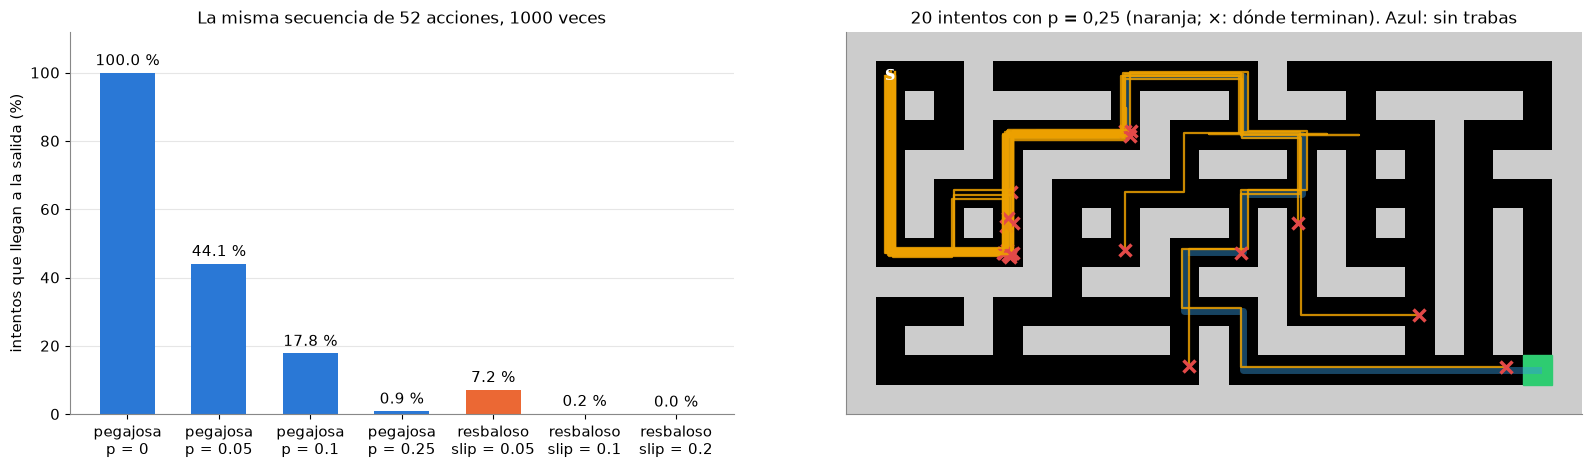

acciones pegajosas p = 0     llega en 100.0% de 1000 intentos
acciones pegajosas p = 0.05  llega en  44.1% de 1000 intentos
acciones pegajosas p = 0.1   llega en  17.8% de 1000 intentos
acciones pegajosas p = 0.25  llega en   0.9% de 1000 intentos
piso resbaloso slip = 0.05 llega en   7.2% de 1000 intentos
piso resbaloso slip = 0.1  llega en   0.2% de 1000 intentos
piso resbaloso slip = 0.2  llega en   0.0% de 1000 intentos


In [19]:
N_INT = 1000
P_PEG = [0.0, 0.05, 0.1, 0.25]
SLIPS = [0.05, 0.1, 0.2]
llega_peg, caminos_peg, llega_slip = {}, {}, {}
for p in P_PEG:
    e = CuevaPegajosa(p_pegajosa=p, cave_map=CUEVA_GRANDE, max_steps=10**9, seed=SEMILLA)
    llega_peg[p], caminos_peg[p] = repetir_secuencia(e, seq, N_INT)
for sl in SLIPS:
    e = CaveEnv(cave_map=CUEVA_GRANDE, max_steps=10**9, slip=sl, seed=SEMILLA)
    llega_slip[sl], _ = repetir_secuencia(e, seq, N_INT)

fig, axs = plt.subplots(1, 2, figsize=(17, 4.8), gridspec_kw={"width_ratios": [1, 1.4]})
etiquetas = [f"pegajosa\np = {p:g}" for p in P_PEG] + [f"resbaloso\nslip = {s:g}" for s in SLIPS]
vals = [100 * llega_peg[p] for p in P_PEG] + [100 * llega_slip[s] for s in SLIPS]
bars = axs[0].bar(etiquetas, vals, color=[COLORES[0]] * len(P_PEG) + [COLORES[1]] * len(SLIPS), width=0.6)
axs[0].bar_label(bars, fmt="%.1f %%", padding=3); axs[0].set_ylim(0, 112); axs[0].grid(axis="x", visible=False)
axs[0].set_ylabel("intentos que llegan a la salida (%)"); axs[0].set_title(f"La misma secuencia de {len(seq)} acciones, {N_INT} veces")
env_ge.plot(ax=axs[1], title="20 intentos con p = 0,25 (naranja; ×: dónde terminan). Azul: sin trabas")
rc = np.array([env_ge.free[s] for s in camino_det]); axs[1].plot(rc[:, 1], rc[:, 0], "-", color="#3498db", lw=5, alpha=0.45)
jit = np.random.default_rng(1).uniform(-0.18, 0.18, size=(20, 2))
for cam, (dy, dx) in zip(caminos_peg[0.25][:20], jit):
    rc = np.array([env_ge.free[s] for s in cam])
    axs[1].plot(rc[:, 1] + dx, rc[:, 0] + dy, "-", color=COLORES[3], lw=1.6, alpha=0.85)
    axs[1].plot(rc[-1, 1] + dx, rc[-1, 0] + dy, "x", color=COLORES[7], ms=9, mew=2.5)
plt.tight_layout(); plt.show()
for p in P_PEG:
    print(f"acciones pegajosas p = {p:<5g} llega en {llega_peg[p]:6.1%} de {N_INT} intentos")
for sl in SLIPS:
    print(f"piso resbaloso slip = {sl:<4g} llega en {llega_slip[sl]:6.1%} de {N_INT} intentos")

Con $p = 0$ la secuencia llega siempre. Con $p = 0{,}05$ (una traba cada 20 pasos, en promedio) llega en el 44 % de los intentos; con $p = 0{,}1$, en el 18 %, y con el $p = 0{,}25$ de Atari, en menos del 1 %. El piso resbaloso es todavía peor, porque cada resbalón manda al agente a un costado: con `slip` = 0,05 llega el 7 %, y con el 0,2 de la clase 4, ninguna vez. Con un poco de azar, cada traba o resbalón deja al agente una casilla corrido, y desde ahí el resto de la secuencia ya no corresponde al lugar donde está: choca, dobla donde no había que doblar, y termina en cualquier parte (las cruces rojas). Una secuencia memorizada **no sabe dónde está**: solo sabe qué botón toca en el paso número tal.

### Paso 3 — Go-Explore volviendo con la secuencia, en una cueva pegajosa

Si Go-Explore vuelve repitiendo secuencias y el entorno es pegajoso, la vuelta ya no llega siempre a la celda elegida, y explora desde otro lado. Medimos qué fracción de las vueltas llegan a la celda elegida y si igual encuentra la salida.

In [20]:
for p in [0.0, 0.1, 0.25]:
    gs = [go_explore(CuevaPegajosa(p_pegajosa=p, cave_map=CUEVA_GRANDE, max_steps=10**9, seed=s), PRESUPUESTO, s, volver="repetir")
          for s in SEMILLAS]
    exactas = np.mean([g["vueltas_exactas"] for g in gs])
    ok = [g["hallazgo"]["pasos"] for g in gs if g["hallazgo"]]
    med = f"{miles(np.median(ok)):>7s}" if ok else "      —"
    print(f"p = {p:<5g} vueltas que llegan a la celda elegida: {exactas:5.1%}   llegó a la salida en {len(ok):2d} de 20 semillas   "
          f"pasos hasta la 1.ª salida (mediana) {med}")

p = 0     vueltas que llegan a la celda elegida: 100.0%   llegó a la salida en 19 de 20 semillas   pasos hasta la 1.ª salida (mediana)  16.612


p = 0.1   vueltas que llegan a la celda elegida: 19.0%   llegó a la salida en  3 de 20 semillas   pasos hasta la 1.ª salida (mediana)  21.124


p = 0.25  vueltas que llegan a la celda elegida: 10.9%   llegó a la salida en  1 de 20 semillas   pasos hasta la 1.ª salida (mediana)  19.723


Con $p = 0{,}1$ solo el 19 % de las vueltas llega a la celda elegida, y con $p = 0{,}25$, el 11 % (las secuencias guardadas son largas, y cada paso es una nueva oportunidad de trabarse). Go-Explore pasa a explorar casi siempre desde otro lado, y con el mismo presupuesto encuentra la salida en 3 de 20 semillas con $p = 0{,}1$ y en 1 de 20 con $p = 0{,}25$, contra 19 de 20 sin trabas. El archivo ya no es una lista de lugares a los que sabe volver. Por eso, en la versión completa, Ecoffet et al. entrenan después una política que aprende a volver **mirando dónde está** (con ruido a propósito durante el entrenamiento), y por eso la evaluación en Atari usa acciones pegajosas: lo que cuenta es una política que funciona, no una secuencia que funcionó una vez.

## ✍️ Ejercicio — Cambien $\varepsilon$ y la bonificación

Cambien `eps_ej`, `c_ej` y `beta_ej` y ejecuten. La celda corre el bandit (100 campañas de 10 000 impresiones) con $\varepsilon$-greedy y UCB, y la cueva grande con «optimista + conteo» (5 semillas, 30 000 pasos).

Antes de ejecutar, **predigan**: con $\varepsilon = 0{,}01$, ¿$\varepsilon$-greedy pierde más o menos que con 0,1? (Pista: piensen en las campañas que se quedan con un anuncio malo.) Con el $c = 1{,}41$ de libro, ¿UCB explora de más o de menos con clics tan raros? En la cueva, ¿qué pasa con $\beta = 0{,}1$, o con $\beta = 0$?

ε-greedy  regret a las 10 000:   65.5   impresiones al mejor: 62.6%
UCB       regret a las 10 000:   30.9   impresiones al mejor: 85.0%


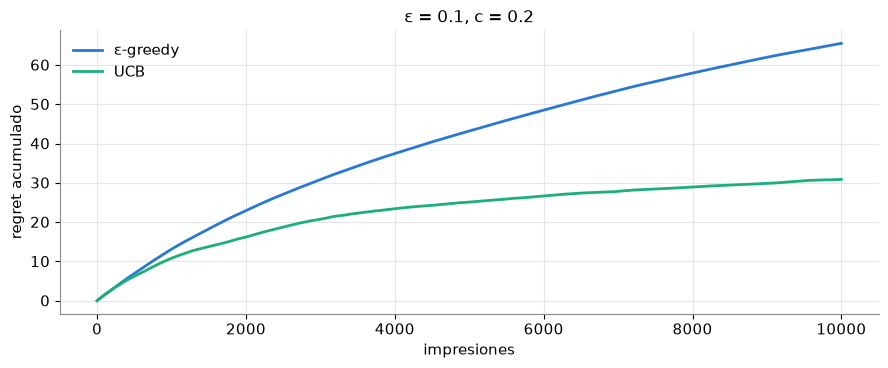

optimista + conteo, β = 0.01 llegó en  5 de 5 semillas (100%)   pasos hasta la 1.ª salida (mediana)     5.369   casillas visitadas 155.0   partidas que salen (últimas 20)  72%


In [21]:
eps_ej = 0.1     # TODO: probá 0.01 y 0.3
c_ej = 0.2       # TODO: probá 0.05 y 1.41
beta_ej = 0.01   # TODO: probá 0 y 0.1

ej = {"ε-greedy": correr_bandit("ε-greedy", CTR, T=10_000, n_campanas=100, seed=1, eps=eps_ej),
      "UCB": correr_bandit("UCB", CTR, T=10_000, n_campanas=100, seed=1, c=c_ej)}
fig, ax = plt.subplots(figsize=(9, 3.8))
for m, r in ej.items():
    ax.plot(r["regret"].mean(0), color=COLOR_MET[m], label=m)
    print(f"{m:9s} regret a las 10 000: {r['regret'][:, -1].mean():6.1f}   impresiones al mejor: {r['al_mejor'].mean():.1%}")
ax.set_xlabel("impresiones"); ax.set_ylabel("regret acumulado"); ax.legend(frameon=False)
ax.set_title(f"ε = {eps_ej}, c = {c_ej}"); plt.tight_layout(); plt.show()

cueva_ej = [explorar(env, PRESUPUESTO, s, eps=0.1, q0=1.0, beta=beta_ej) for s in range(5)]
resumir(f"optimista + conteo, β = {beta_ej}", cueva_ej, PRESUPUESTO);

**Lo que encontramos** (¿qué $\varepsilon$ y qué $c$ pierden menos? ¿por qué un $c$ demasiado grande también pierde? ¿cambia algo $\beta$ en la cueva?):

-

## Preguntas para pensar

1. En la sección 2, la prueba A/B fija a veces elegía mal y seguía perdiendo para siempre. ¿Qué tendría que cambiar en una empresa para pasar de «probar y después decidir» a «probar mientras se decide», como UCB? ¿Quién paga las impresiones de prueba?
2. En la sección 5, la bonificación por conteo sola hacía que el agente diera vueltas por lo conocido. ¿Conocen situaciones en las que se premia «volver a lo de siempre» creyendo que se premia la curiosidad?
3. Go-Explore necesita poder volver. Un robot real no puede restaurar el estado, y con un piso que resbala tampoco puede confiar en repetir los mismos movimientos. ¿Qué tendría que aprender para volver de verdad?

## Próxima clase

Todo esto fue con una tabla: una fila por casilla, una cuenta de visitas por casilla. En una pantalla de Atari no hay tabla posible, porque casi nunca se repite exactamente la misma imagen. En la clase 8, **de la tabla a la red**: reemplazar la tabla $Q$ por una red neuronal, que vemos desde cero.